## Imports and Tokens

In [767]:
from matplotlib import pyplot as plt
import pandas as pd
import json
import random
from src.utils.entsoe_client import fetch_and_save_spot_prices
import json


# Define the API tokens
# Personal renewables.ninja API token
with open(r"D:\Dokumente\Studium\20242025 WS\WattWise\Repo\wattWise\secrets.json") as f:
    secrets = json.load(f)

ninja_token = secrets.get("ninja_token")
entsoe_api_key = secrets.get("entsoe_api_key")


## Data Loading and Cleaning

#### Spot data - ENTSOE API

In [682]:
# Spot market data 2019
country_code = 'DE_LU'  # 'DE_LU' for 2018 - 2023 and 'DE_AT_LU' for < 2018
spot_directory = 'data/entsoe_data/normal_hourly'
start_date = '2019-01-01'
end_date = '2019-12-31'

#EntsoE API call
#fetch_and_save_spot_prices(entsoe_api_key, country_code, start_date, end_date, spot_directory)

# Spot market data 2020
country_code = 'DE_LU'  # 'DE_LU' for 2018 - 2023 and 'DE_AT_LU' for < 2018
spot_directory = 'data/entsoe_data/normal_hourly'
start_date = '2020-01-01'
end_date = '2020-12-31'

#EntsoE API call
#fetch_and_save_spot_prices(entsoe_api_key, country_code, start_date, end_date, spot_directory)

# Load the data as a pandas DataFrame
spot_prices_2019 = data = pd.read_csv(
    'data/entsoe_data/normal_hourly/Spot_prices_DE_LU_2019.csv',
    delimiter=';',  # Separator between columns
    decimal=',',    # Comma used as decimal point
    parse_dates=['Date (CET)'],  # Parse the date column into datetime
    dayfirst=True   # Day comes first in the date format
)
#€/ MWH in ct/KWH umwandelm
spot_prices_2019['Price ct/KWH'] = spot_prices_2019['Price (€/MWh)'].apply(lambda x: x/1000 * 100)

print(spot_prices_2019.head())
print("Average price 2019: ", spot_prices_2019['Price ct/KWH'].mean())

#2020
spot_prices_2020 = data = pd.read_csv(
    'data/entsoe_data/normal_hourly/Spot_prices_DE_LU_2020.csv',
    delimiter=';',  # Separator between columns
    decimal=',',    # Comma used as decimal point
    parse_dates=['Date (CET)'],  # Parse the date column into datetime
    dayfirst=True   # Day comes first in the date format
)
#€/ MWH in ct/KWH umwandelm
spot_prices_2020['Price ct/KWH'] = spot_prices_2020['Price (€/MWh)'].apply(lambda x: x/1000 * 100)

#print("Average price 2020: ", spot_prices_2020['Price ct/KWH'].mean())

spot_prices_2020

C:\Users\Hannah Heimpel\AppData\Local\Temp\ipykernel_21192\1402570545.py:20: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  spot_prices_2019 = data = pd.read_csv(


           Date (CET)  Price (€/MWh)  Price ct/KWH
0 2019-01-01 00:00:00          28.32         2.832
1 2019-01-01 01:00:00          10.07         1.007
2 2019-01-01 02:00:00          -4.08        -0.408
3 2019-01-01 03:00:00          -9.91        -0.991
4 2019-01-01 04:00:00          -7.41        -0.741
Average price 2019:  3.7680148809523812


C:\Users\Hannah Heimpel\AppData\Local\Temp\ipykernel_21192\1402570545.py:34: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  spot_prices_2020 = data = pd.read_csv(


,Date (CET),Price (€/MWh),Price ct/KWH
0,2020-01-01 00:00:00,41.88,4.188
1,2020-01-01 01:00:00,38.60,3.860
2,2020-01-01 02:00:00,36.55,3.655
3,2020-01-01 03:00:00,32.32,3.232
4,2020-01-01 04:00:00,30.85,3.085
...,...,...,...
8755,2020-12-30 19:00:00,53.60,5.360
8756,2020-12-30 20:00:00,52.38,5.238
8757,2020-12-30 21:00:00,46.88,4.688
8758,2020-12-30 22:00:00,43.22,4.322


#### Electricity Prices over the years:  
Source: https://www.bdew.de/service/daten-und-grafiken/bdew-strompreisanalyse/
![image.png](attachment:image.png)

    Year  Beschaffung_Vetrieb  Netzentgelt  Mehrwertsteuer  Summe  Sonstige
0   2024                17.94        11.53            6.60  41.35      5.28
1   2023                23.83         9.52            7.30  45.73      5.08
2   2022                16.97         8.08            6.05  37.91      6.81
3   2021                 7.93         7.80            5.13  32.16     11.30
4   2020                 7.51         7.75            5.08  31.81     11.47
5   2019                 7.09         7.39            4.86  30.46     11.12
6   2018                 7.09         7.29            4.71  29.47     10.38
7   2017                 7.05         7.51            4.67  29.28     10.05
8   2016                 7.05         7.51            4.60  28.80      9.64
9   2015                 7.38         6.63            4.58  28.70     10.11
10  2014                 7.38         6.63            4.56  29.14     10.57


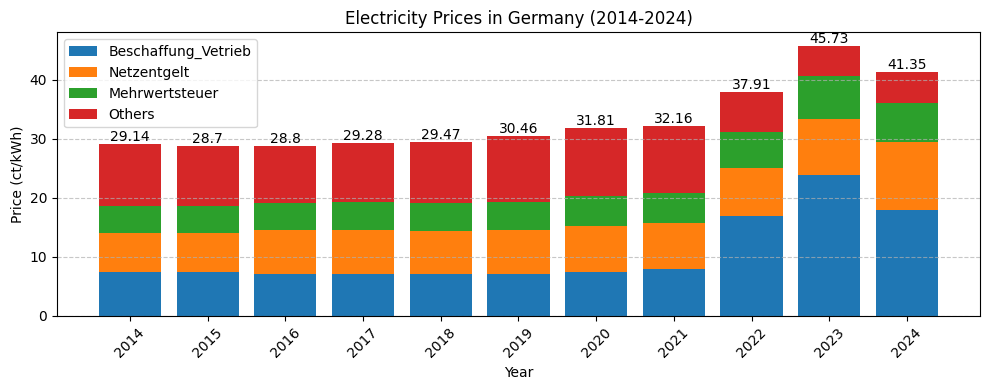

In [683]:
electricity_prices = {
    "Year": [2024, 2023, 2022, 2021, 2020, 2019, 2018, 2017, 2016, 2015, 2014],
    "Beschaffung_Vetrieb": [17.94, 23.83, 16.97, 7.93, 7.51, 7.09, 7.09, 7.05, 7.05, 7.38, 7.38],
    "Netzentgelt": [11.53, 9.52, 8.08, 7.80, 7.75, 7.39, 7.29, 7.51, 7.51, 6.63, 6.63],
    "Mehrwertsteuer": [6.60, 7.30, 6.05, 5.13, 5.08, 4.86, 4.71, 4.67, 4.60, 4.58, 4.56],
    "Summe": [41.35, 45.73, 37.91, 32.16, 31.81, 30.46, 29.47, 29.28, 28.80, 28.70, 29.14]
} #' IN kwH'

# Create DataFrame and add Sonstige column (EEG-Umlage, KWK-Aufschlag, Stromsteuer,...))
electricity_prices_df = pd.DataFrame(electricity_prices)
electricity_prices_df['Sonstige'] = electricity_prices_df['Summe'] - (electricity_prices_df['Beschaffung_Vetrieb'] + electricity_prices_df['Netzentgelt'] + electricity_prices_df['Mehrwertsteuer'])
print(electricity_prices_df)

# Plot the data as a stacked bar chart
plt.figure(figsize=(10,4))
plt.bar(electricity_prices_df['Year'], electricity_prices_df['Beschaffung_Vetrieb'], label='Beschaffung_Vetrieb')
plt.bar(electricity_prices_df['Year'], electricity_prices_df['Netzentgelt'], 
        bottom=electricity_prices_df['Beschaffung_Vetrieb'], label='Netzentgelt')
plt.bar(electricity_prices_df['Year'], electricity_prices_df['Mehrwertsteuer'], 
        bottom=electricity_prices_df['Beschaffung_Vetrieb'] + electricity_prices_df['Netzentgelt'], label='Mehrwertsteuer')
plt.bar(electricity_prices_df['Year'], electricity_prices_df['Sonstige'],bottom=electricity_prices_df['Beschaffung_Vetrieb'] + electricity_prices_df['Netzentgelt'] + electricity_prices_df['Mehrwertsteuer'], label='Others')
plt.xlabel('Year')
plt.ylabel('Price (ct/kWh)')
for i in range(len(electricity_prices_df)):
    plt.text(electricity_prices_df['Year'][i], electricity_prices_df['Summe'][i] + 0.5, str(electricity_prices_df['Summe'][i]), ha='center') #add values
plt.title('Electricity Prices in Germany (2014-2024)')
plt.xticks(electricity_prices_df['Year'], rotation=45)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

#### Load Household data

- filtered_df = Data of all households in 2019
- filtered_df_test = Data of all households in 2020

In [684]:
#Load pickle into dataframe
hh_path = r"local_input_data\1920 Final Data w. Additional Features HH Hourly Agg.pkl"
start_date = '2019-01-01'
end_date = '2019-12-31'
start_date_test = '2020-01-01'
end_date_test = '2020-12-31'
keyword = 'SFH' # Single Family Households

data_allhouseholds = pd.read_pickle(hh_path)
mask_model = (data_allhouseholds.index >= start_date) & (data_allhouseholds.index < end_date)
mask_test = (data_allhouseholds.index >= start_date_test) & (data_allhouseholds.index < end_date_test)


##### 2019

In [685]:
data_allhouseholds_model = data_allhouseholds.loc[mask_model]

# Extract columns that contain the keyword in their name
filtered_df = data_allhouseholds_model.filter(like=keyword)
filtered_df = filtered_df.drop(columns=['SFH34_P_TOT']) # TODO: SHOW WHY Household 34 is shit

# turn unit to kWh
filtered_df = filtered_df/1000

print("Number of households: ", len(filtered_df.columns))
filtered_df.head()


Number of households:  21


,SFH3_P_TOT,SFH4_P_TOT,SFH5_P_TOT,SFH7_P_TOT,SFH9_P_TOT,SFH12_P_TOT,SFH14_P_TOT,SFH16_P_TOT,SFH18_P_TOT,SFH19_P_TOT,...,SFH21_P_TOT,SFH22_P_TOT,SFH27_P_TOT,SFH28_P_TOT,SFH29_P_TOT,SFH30_P_TOT,SFH32_P_TOT,SFH36_P_TOT,SFH38_P_TOT,SFH39_P_TOT
date,,,,,,,,,,,,,,,,,,,,,
2019-01-01 00:00:00+00:00,0.161493,0.378307,0.555783,0.472945,0.276283,0.141515,1.263900,0.138280,0.167612,0.204542,...,0.187705,0.278985,0.095981,0.091195,0.130055,0.183680,0.172490,0.341785,0.552966,0.137806
2019-01-01 01:00:00+00:00,0.201888,0.379044,0.446765,0.303302,0.254865,0.137292,1.251248,0.109699,0.171209,0.207164,...,0.198733,0.309711,0.097085,0.177395,0.111404,0.080881,0.115421,0.335813,0.326356,0.146449
2019-01-01 02:00:00+00:00,0.156627,0.381565,0.301362,0.142379,0.198773,0.133582,1.121481,0.072142,0.159650,0.214528,...,0.192340,0.399156,0.102519,0.236366,0.118093,0.119899,0.145594,0.211437,0.263901,0.156046
2019-01-01 03:00:00+00:00,0.155399,0.427539,0.307746,0.152653,0.241786,0.147410,0.990431,0.102894,0.124849,0.194947,...,0.224510,0.149937,0.096335,0.186000,0.116369,0.077734,0.112445,0.146979,0.303394,0.176267
2019-01-01 04:00:00+00:00,0.112611,0.309020,0.326347,0.208406,0.165343,0.126375,0.314959,0.091286,0.175570,0.283466,...,0.182807,0.186482,0.095063,0.171690,0.122021,0.076919,0.078177,0.141085,0.290612,0.286422


##### 2020

In [686]:
data_allhouseholds_test = data_allhouseholds.loc[mask_test]

# Extract columns that contain the keyword in their name
filtered_df_test = data_allhouseholds_test.filter(like=keyword)
filtered_df_test = filtered_df_test.drop(columns=['SFH34_P_TOT'])

# turn unit to kWh
filtered_df_test = filtered_df_test/1000

print("Number of households: ", len(filtered_df_test.columns))

filtered_df_test

Number of households:  21


,SFH3_P_TOT,SFH4_P_TOT,SFH5_P_TOT,SFH7_P_TOT,SFH9_P_TOT,SFH12_P_TOT,SFH14_P_TOT,SFH16_P_TOT,SFH18_P_TOT,SFH19_P_TOT,...,SFH21_P_TOT,SFH22_P_TOT,SFH27_P_TOT,SFH28_P_TOT,SFH29_P_TOT,SFH30_P_TOT,SFH32_P_TOT,SFH36_P_TOT,SFH38_P_TOT,SFH39_P_TOT
date,,,,,,,,,,,,,,,,,,,,,
2020-01-01 00:00:00+00:00,0.163916,0.373391,0.426055,0.175637,0.880133,0.147927,1.028024,0.240754,0.093248,0.596717,...,0.276218,0.344925,0.088926,0.599022,0.111477,0.150296,0.199717,0.149463,0.404039,0.151883
2020-01-01 01:00:00+00:00,0.096884,0.433742,0.414172,0.132504,0.568079,0.142868,0.659489,0.181140,0.120597,1.297585,...,0.233408,0.200887,0.095167,0.585296,0.096038,0.081426,0.206756,0.157918,0.434017,0.151909
2020-01-01 02:00:00+00:00,0.207420,0.455052,0.373124,0.198556,0.641215,0.136044,0.358423,0.109398,0.137314,1.125870,...,0.193405,0.175490,0.103124,0.578868,0.098231,0.083770,0.138144,0.159315,0.546359,0.171845
2020-01-01 03:00:00+00:00,0.109694,0.377600,0.365616,0.150788,0.538791,0.135456,0.349706,0.102048,0.093597,0.299468,...,0.214475,0.146496,0.093065,0.255038,0.100640,0.060413,0.129610,0.138526,0.334807,0.128404
2020-01-01 04:00:00+00:00,0.193015,0.277767,0.374640,0.100247,0.368989,0.145098,0.348721,0.110583,0.123097,0.319027,...,0.205340,0.220397,0.076818,0.161516,0.108735,0.090928,0.077703,0.139926,0.224035,0.150912
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2020-12-30 19:00:00+00:00,0.285882,1.288372,0.487239,0.444430,0.621300,0.287039,1.417525,0.368618,0.992046,0.363517,...,0.299486,1.921150,0.119291,0.597287,0.373720,0.445905,0.541438,0.217190,1.002722,0.271178
2020-12-30 20:00:00+00:00,0.177044,0.443794,0.510834,0.503695,0.597298,0.328044,0.874725,0.298788,0.866079,0.226329,...,0.297135,0.430116,0.114994,0.569243,0.184183,0.223751,0.422432,0.210398,0.553453,0.291510
2020-12-30 21:00:00+00:00,0.240316,0.433245,0.352619,0.454367,0.504256,0.287266,1.038879,0.294333,0.427432,0.178664,...,0.209374,0.404800,0.079628,0.580204,0.197486,0.110087,0.342846,0.187408,0.559419,0.214913


# Models

## 1. Model: Standardlastprofil: 
- Load data: Datensatz: SLP 2019 der Stadtwerke Groß-Gerau Versorgung GmbH: https://ggv-energie.de/cms/netz/allgemeine-daten/netzbilanzierung-download-aller-profile.php
  - Datensatz enthält Standardlastprofil eines typischen Einfamilien Haushalt (H00)
- Vorhersage für 2020, auf Basis des Standardlastprofils
  - Standard Werktag auf Basis vom 
  - Standard Wochenende
  - Verbrauch des Haushalts von 2019 erfragen (hier irrelevant, da alle auf 3000 normiert sind)
- Vergleich Load Forecast mit realem Datensatz von allen Haushalten 2020
- Vergleich Jahreskosten mit realem Datensatz und Forecast von 2020 von allen Haushalten



### Load SLP data and normalize to 3000kwh

Load Data

In [687]:
file_path = r"D:\Dokumente\Studium\20242025 WS\WattWise\Repo\wattWise\data\slp\GGV_SLP_1000_MWh_2019_01.xlsx"
sheet_name = "15Min - SLP 2019" # Single Load Profile 2019

data_15min_slp_2019 = pd.read_excel(file_path, sheet_name=sheet_name)
data_15min_slp_2019.head() 

,Messwert-Nr.,Wochentag,Datum,Zeitstempel von,Zeitstempel bis,MP von,MP bis,H00 [kW],H00 [kWh]
0,1,2,2019-01-01,2019-01-01 00:00:00,2019-01-01 00:15:00,00:00,00:15,145.200,36.300
1,2,2,2019-01-01,2019-01-01 00:15:00,2019-01-01 00:30:00,00:15,00:30,140.112,35.028
2,3,2,2019-01-01,2019-01-01 00:30:00,2019-01-01 00:45:00,00:30,00:45,135.720,33.930
3,4,2,2019-01-01,2019-01-01 00:45:00,2019-01-01 01:00:00,00:45,01:00,130.732,32.683
4,5,2,2019-01-01,2019-01-01 01:00:00,2019-01-01 01:15:00,01:00,01:15,127.236,31.809


Data Prepapration

In [688]:
data_15min_slp_2019.drop(columns=['Messwert-Nr.','MP von', 'MP bis'], inplace=True)

In [689]:
#Fasse Zeitstempel pro Stunde zusammen und summiere H00 [kW] in neuer df
data_15min_slp_2019['Time'] = data_15min_slp_2019['Zeitstempel von'].dt.floor('h')

data_slp_hourly_2019 = data_15min_slp_2019.groupby('Time').agg({'H00 [kW]': 'sum'}).reset_index()
data_slp_hourly_2019['H00 [kWh]'] = data_slp_hourly_2019['H00 [kW]'] / 4 
#add 'Wochentag'
data_slp_hourly_2019['Weekday'] = data_slp_hourly_2019['Time'].dt.day_name()

#add Arbeitstag oder Wochenende als neue Spalte
data_slp_hourly_2019['Weekend'] = data_slp_hourly_2019['Weekday'].apply(lambda x: 1 if x in ['Saturday', 'Sunday'] else 0)

#add Hour and save as int
data_slp_hourly_2019['Hour'] = data_slp_hourly_2019['Time'].dt.time
data_slp_hourly_2019['Hour'] = data_slp_hourly_2019['Hour'].apply(lambda x: x.hour)

#Normalizing the values to a "average household" with 3000 kWh  
data_slp_hourly_2019['H00_Norm [kWh]'] = data_slp_hourly_2019['H00 [kWh]'] /data_slp_hourly_2019['H00 [kWh]'].sum()*3000

data_slp_hourly_2019

,Time,H00 [kW],H00 [kWh],Weekday,Weekend,Hour,H00_Norm [kWh]
0,2019-01-01 00:00:00,551.764,137.941,Tuesday,0,0,0.413823
1,2019-01-01 01:00:00,492.584,123.146,Tuesday,0,1,0.369438
2,2019-01-01 02:00:00,448.376,112.094,Tuesday,0,2,0.336282
3,2019-01-01 03:00:00,418.236,104.559,Tuesday,0,3,0.313677
4,2019-01-01 04:00:00,386.208,96.552,Tuesday,0,4,0.289656
...,...,...,...,...,...,...,...
8754,2019-12-31 19:00:00,656.444,164.111,Tuesday,0,19,0.492333
8755,2019-12-31 20:00:00,574.216,143.554,Tuesday,0,20,0.430662
8756,2019-12-31 21:00:00,557.048,139.262,Tuesday,0,21,0.417786
8757,2019-12-31 22:00:00,640.876,160.219,Tuesday,0,22,0.480657


### Prediction for 2020
auf Basis des Standardlastprofils
  - Standard Werktag berechnen 
  - Standard Wochenende
  - Diese WErte auf Prediciton profil von 2020 übertragen.
  - Verbrauch des Haushalts von 2019 erfragen (hier irrelevant, da alle auf 3000 normiert sind)


In [690]:
#Calculate an average Weekday (Monday - Fridaay means Weekend == 0)
weekday_data = data_slp_hourly_2019[data_slp_hourly_2019['Weekend'] == 0]

average_weekday = weekday_data.groupby('Hour').agg({'H00_Norm [kWh]': 'mean'}).reset_index()

average_weekday.head()

,Hour,H00_Norm [kWh]
0,0,0.263477
1,1,0.231250
2,2,0.221361
3,3,0.219777
4,4,0.227036


Calculate an average Weekday (Monday - Fridaay means Weekend == 0)

In [691]:
#Calculate an average Weekday (Saturday/Sunday means Weekend == 1

weekendday_data = data_slp_hourly_2019[data_slp_hourly_2019['Weekend'] == 1]
average_weekendday = weekendday_data.groupby('Hour').agg({'H00_Norm [kWh]': 'mean'}).reset_index()

average_weekendday.head()

,Hour,H00_Norm [kWh]
0,0,0.279139
1,1,0.241221
2,2,0.226147
3,3,0.219243
4,4,0.217916


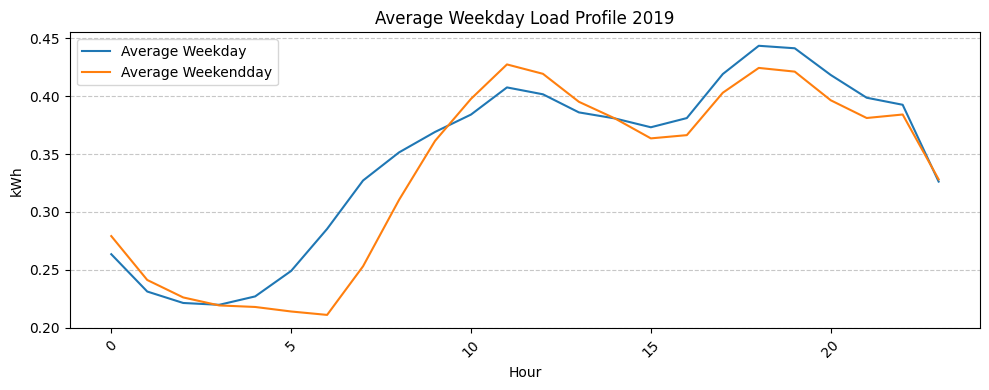

In [692]:
#Plots
#Plot
plt.figure(figsize=(10,4))
plt.plot(average_weekday['Hour'], average_weekday['H00_Norm [kWh]'], label='Average Weekday')
plt.plot(average_weekendday['Hour'], average_weekendday['H00_Norm [kWh]'], label='Average Weekendday')
plt.xlabel('Hour')
plt.ylabel('kWh')
plt.title('Average Weekday Load Profile 2019')
plt.xticks(rotation=45)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


#### Prediciton profil von 2020 erstellen
- range aufstellen
- if Weekday -> average_weekday matchen zu Kalender auf Basis von Stunden
- if Weekend -> average_weekendday matchen zu Kalender auf Basis von Stunden

In [693]:
# Define the target full-year date range
start_date_2020 = '2020-01-01'
end_date_2020 = '2020-12-31'
date_range = pd.date_range(start=start_date_2020, end=end_date_2020, freq='h', tz='UTC') # hourly data

# Create a DataFrame with the full-year date range
model1_prediciton_2020 = pd.DataFrame(index=date_range)

# add Day informations
model1_prediciton_2020['Hour'] = model1_prediciton_2020.index.hour
model1_prediciton_2020['Weekday'] = model1_prediciton_2020.index.day_name()
model1_prediciton_2020['Weekend'] = model1_prediciton_2020['Weekday'].apply(lambda x: 1 if x in ['Saturday', 'Sunday'] else 0)

model1_prediciton_2020['H00_predicted [kWh]']=0
model1_prediciton_2020 = model1_prediciton_2020[:-1] #delete last row (0Uhr)

model1_prediciton_2020.head()

,Hour,Weekday,Weekend,H00_predicted [kWh]
2020-01-01 00:00:00+00:00,0,Wednesday,0,0
2020-01-01 01:00:00+00:00,1,Wednesday,0,0
2020-01-01 02:00:00+00:00,2,Wednesday,0,0
2020-01-01 03:00:00+00:00,3,Wednesday,0,0
2020-01-01 04:00:00+00:00,4,Wednesday,0,0


In [694]:
# add information for model1_prediciton_2020['H00_predicted [kWh]']. If Weekday == 0 then take average_weekday else average_weekendday and match with Hour
for index, row in model1_prediciton_2020.iterrows():
    if row['Weekend'] == 0:
        model1_prediciton_2020.loc[index, 'H00_predicted [kWh]'] = average_weekday[average_weekday['Hour'] == row['Hour']]['H00_Norm [kWh]'].values[0]
    else:
        model1_prediciton_2020.loc[index, 'H00_predicted [kWh]'] = average_weekendday[average_weekendday['Hour'] == row['Hour']]['H00_Norm [kWh]'].values[0]


C:\Users\Hannah Heimpel\AppData\Local\Temp\ipykernel_21192\2267906313.py:4: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.2634770519382463' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  model1_prediciton_2020.loc[index, 'H00_predicted [kWh]'] = average_weekday[average_weekday['Hour'] == row['Hour']]['H00_Norm [kWh]'].values[0]


In [695]:
model1_prediciton_2020

,Hour,Weekday,Weekend,H00_predicted [kWh]
2020-01-01 00:00:00+00:00,0,Wednesday,0,0.263477
2020-01-01 01:00:00+00:00,1,Wednesday,0,0.231250
2020-01-01 02:00:00+00:00,2,Wednesday,0,0.221361
2020-01-01 03:00:00+00:00,3,Wednesday,0,0.219777
2020-01-01 04:00:00+00:00,4,Wednesday,0,0.227036
...,...,...,...,...
2020-12-30 19:00:00+00:00,19,Wednesday,0,0.441350
2020-12-30 20:00:00+00:00,20,Wednesday,0,0.418301
2020-12-30 21:00:00+00:00,21,Wednesday,0,0.398629
2020-12-30 22:00:00+00:00,22,Wednesday,0,0.392547


### Test the model	
- Vergleich mit realem Datensatz von allen Haushalten. Berechne MAPE
- Preisberechnugn für 2020

In [696]:
# Define actual_load_profile2020
actual_load_profile2020 = filtered_df_test

# Display the actual load profile for 2020
actual_load_profile2020.head()

#Normalize to 3000 kWh
for column in actual_load_profile2020.columns:
    actual_load_profile2020[column] = actual_load_profile2020[column] / actual_load_profile2020[column].sum() * 3000

# Display the actual load profile for 2020
actual_load_profile2020.head()

,SFH3_P_TOT,SFH4_P_TOT,SFH5_P_TOT,SFH7_P_TOT,SFH9_P_TOT,SFH12_P_TOT,SFH14_P_TOT,SFH16_P_TOT,SFH18_P_TOT,SFH19_P_TOT,...,SFH21_P_TOT,SFH22_P_TOT,SFH27_P_TOT,SFH28_P_TOT,SFH29_P_TOT,SFH30_P_TOT,SFH32_P_TOT,SFH36_P_TOT,SFH38_P_TOT,SFH39_P_TOT
date,,,,,,,,,,,,,,,,,,,,,
2020-01-01 00:00:00+00:00,0.235083,0.338549,0.421355,0.165795,0.536347,0.130392,1.260980,0.312827,0.100835,0.529366,...,0.316237,0.288901,0.238178,0.565123,0.230555,0.195297,0.216712,0.168074,0.314421,0.188607
2020-01-01 01:00:00+00:00,0.138948,0.393269,0.409602,0.125080,0.346184,0.125933,0.808933,0.235367,0.130411,1.151129,...,0.267225,0.168259,0.254894,0.552174,0.198624,0.105806,0.224350,0.177582,0.337750,0.188640
2020-01-01 02:00:00+00:00,0.297474,0.412591,0.369007,0.187430,0.390752,0.119917,0.439644,0.142148,0.148487,0.998795,...,0.221426,0.146986,0.276205,0.546109,0.203159,0.108852,0.149899,0.179153,0.425174,0.213396
2020-01-01 03:00:00+00:00,0.157319,0.342366,0.361583,0.142339,0.328336,0.119399,0.428951,0.132597,0.101213,0.265667,...,0.245548,0.122702,0.249265,0.240605,0.208143,0.078502,0.140639,0.155775,0.260545,0.159452
2020-01-01 04:00:00+00:00,0.276814,0.251848,0.370506,0.094630,0.224859,0.127898,0.427743,0.143687,0.133114,0.283019,...,0.235090,0.184600,0.205749,0.152376,0.224884,0.118153,0.084315,0.157349,0.174343,0.187402


In [730]:
# NMAE
def calculate_nmae(actual_df, predicted_df):
    """
    Calculate the Normalized Mean Absolute Error (NMAE) between actual and predicted values.

    Parameters:
    - actual_df (pd.DataFrame or pd.Series): The DataFrame or Series containing actual values.
    - predicted_df (pd.DataFrame or pd.Series): The DataFrame or Series containing predicted values.

    Returns:
    - float: The NMAE value as a percentage.
    """
    if not actual_df.index.equals(predicted_df.index):
        raise ValueError("The indices of actual_df and predicted_df must match.")
    absolute_errors = abs(actual_df - predicted_df)
    mae = absolute_errors.mean() # Compute the Mean Absolute Error (MAE)
    nmae = mae / actual_df.mean() # Compute the Normalized Mean Absolute Error (NMAE)
    return 100 * nmae

# Calculate NMAE for each SFH column
nmae_results_m1 = {}
for column in actual_load_profile2020.columns:
    nmae_m1 = calculate_nmae(actual_load_profile2020[column], model1_prediciton_2020['H00_predicted [kWh]'])
    nmae_results_m1[column] = nmae_m1
    print(f"NMAE for {column}: {nmae_m1:.2f} %")
nmae_average_m1 = sum(nmae_results_m1.values())/len(nmae_results_m1)
nmae_average_m1


NMAE for SFH3_P_TOT: 58.07 %
NMAE for SFH4_P_TOT: 39.39 %
NMAE for SFH5_P_TOT: 50.62 %
NMAE for SFH7_P_TOT: 50.45 %
NMAE for SFH9_P_TOT: 62.75 %
NMAE for SFH12_P_TOT: 67.07 %
NMAE for SFH14_P_TOT: 60.65 %
NMAE for SFH16_P_TOT: 69.87 %
NMAE for SFH18_P_TOT: 71.88 %
NMAE for SFH19_P_TOT: 43.41 %
NMAE for SFH20_P_TOT: 49.42 %
NMAE for SFH21_P_TOT: 37.17 %
NMAE for SFH22_P_TOT: 48.06 %
NMAE for SFH27_P_TOT: 34.20 %
NMAE for SFH28_P_TOT: 57.14 %
NMAE for SFH29_P_TOT: 52.29 %
NMAE for SFH30_P_TOT: 61.87 %
NMAE for SFH32_P_TOT: 48.67 %
NMAE for SFH36_P_TOT: 54.38 %
NMAE for SFH38_P_TOT: 33.25 %
NMAE for SFH39_P_TOT: 35.44 %


np.float64(51.71638548702025)

#### Cost Comparison
- price calculation 2020 (dynamic, static prices)
- Predicted costs (dynamic, static prices)
- actual costs (dynamic, static prices)
- Auswertung

In [698]:
spot_prices_2020
#use 'Date (CET' as index
spot_prices_2020.set_index('Date (CET)', inplace=True)
spot_prices_2020


,Price (€/MWh),Price ct/KWH
Date (CET),,
2020-01-01 00:00:00,41.88,4.188
2020-01-01 01:00:00,38.60,3.860
2020-01-01 02:00:00,36.55,3.655
2020-01-01 03:00:00,32.32,3.232
2020-01-01 04:00:00,30.85,3.085
...,...,...
2020-12-30 19:00:00,53.60,5.360
2020-12-30 20:00:00,52.38,5.238
2020-12-30 21:00:00,46.88,4.688


In [745]:
# Preisberechnung

# Define the missing variables # TODO: Replace with actual values
consumption_dependent_fixed_costs = 19.71  # ct per KwH 2024 value Tibber - Example value, replace with actual value
Consumption_independent_base_price = 15.73  # €/Monat - 2024 value Tibber - Example value, replace with actual value

# Calculate dynamic price in 2020 und rechne Cent in euro
dynamic_price_per_kwh_2020 = (spot_prices_2020['Price ct/KWH'] + consumption_dependent_fixed_costs)/100
dynamic_price_permonth = Consumption_independent_base_price # ist schon in Euro!

average_dynamic_price_per_kwh_2020 = dynamic_price_per_kwh_2020.mean()
print("Average dynamic price per kWh in 2020 [Euro] : ", average_dynamic_price_per_kwh_2020)
# Calculate fixed price in 2020
fixed_price_per_kwh = electricity_prices_df.loc[electricity_prices_df['Year'] == 2020, 'Summe'].values[0]/100 # /100, damit in Euro
print("Fixed price per kWh in 2020 [Euro] : ", fixed_price_per_kwh)

Average dynamic price per kWh in 2020 [Euro] :  0.22752624771689497
Fixed price per kWh in 2020 [Euro] :  0.3181


##### Actual Costs

In [700]:
# Calculate the annual costs for each household based on dynamic price

def calculate_annual_dynamic_costs(df_load_profile, df_dynamic_price):
    # Ensure both indices are timezone-aware
    if df_load_profile.index.tz is None:
        df_load_profile.index = df_load_profile.index.tz_localize('UTC')
    if df_dynamic_price.index.tz is None:
        df_dynamic_price.index = df_dynamic_price.index.tz_localize('UTC')
    
    # Calculate the total costs of the household
    annual_costs = ((df_load_profile * df_dynamic_price).sum(axis=0))
    return annual_costs

# Calculate the annual costs for each household based on static price
def calculate_annual_static_costs(df_load_profile, static_price_per_kwh):
    
    annual_costs = (df_load_profile.sum(axis=0) * static_price_per_kwh)

    return annual_costs

In [758]:
# Calculate the annual costs for each household and compare fixed and dynamic prices

print("------Result------")

sum_difference = 0
list_of_households_fixed_cheaper = []
list_of_households_dynamic_cheaper = []

dynamic_costs_allhouseholds_actual = []

for column in actual_load_profile2020.columns:
    print(f"Household: ", column)
    annual_costs_dynamic_actual = calculate_annual_dynamic_costs(actual_load_profile2020[column], dynamic_price_per_kwh_2020) + dynamic_price_permonth*12 #in €
    dynamic_costs_allhouseholds_actual.append(annual_costs_dynamic_actual)
    print(f"Annual actual costs for {column} based on dynamic prices: {annual_costs_dynamic_actual:.2f} €")
    annual_costs_static_actual = calculate_annual_static_costs(actual_load_profile2020[column], fixed_price_per_kwh)#in €
    print(f"Annual actual costs for {column} based on fixed prices: {annual_costs_static_actual:.2f} €")

    """
    if annual_costs_dynamic_actual < annual_costs_static_actual:
        print("Dynamic pricing is cheaper than fixed pricing. Difference: ", annual_costs_static_actual - annual_costs_dynamic_actual, "Euro")
        list_of_households_dynamic_cheaper_m1.append(column)
    else:
        print("Fixed pricing is cheaper than dynamic pricing. Difference: ", annual_costs_dynamic_actual - annual_costs_static_actual, "Euro")
        list_of_households_fixed_cheaper_m1.append(column)
   

print("List of households where fixed pricing is cheaper than dynamic pricing: ", list_of_households_fixed_cheaper)
print("List of households where dynamic pricing is cheaper than fixed pricing: ", list_of_households_dynamic_cheaper)
"""
dynamic_costs_allhouseholds_actual


------Result------
Household:  SFH3_P_TOT
Annual actual costs for SFH3_P_TOT based on dynamic prices: 867.47 €
Annual actual costs for SFH3_P_TOT based on fixed prices: 954.30 €
Household:  SFH4_P_TOT
Annual actual costs for SFH4_P_TOT based on dynamic prices: 874.87 €
Annual actual costs for SFH4_P_TOT based on fixed prices: 954.30 €
Household:  SFH5_P_TOT
Annual actual costs for SFH5_P_TOT based on dynamic prices: 873.21 €
Annual actual costs for SFH5_P_TOT based on fixed prices: 954.30 €
Household:  SFH7_P_TOT
Annual actual costs for SFH7_P_TOT based on dynamic prices: 878.49 €
Annual actual costs for SFH7_P_TOT based on fixed prices: 954.30 €
Household:  SFH9_P_TOT
Annual actual costs for SFH9_P_TOT based on dynamic prices: 873.77 €
Annual actual costs for SFH9_P_TOT based on fixed prices: 954.30 €
Household:  SFH12_P_TOT
Annual actual costs for SFH12_P_TOT based on dynamic prices: 873.41 €
Annual actual costs for SFH12_P_TOT based on fixed prices: 954.30 €
Household:  SFH14_P_TOT


[np.float64(867.4651590066242),
 np.float64(874.8673258759051),
 np.float64(873.2135315170656),
 np.float64(878.4854814026756),
 np.float64(873.7724476634021),
 np.float64(873.4087447392734),
 np.float64(881.3787373741309),
 np.float64(876.4832788406376),
 np.float64(876.2991991437011),
 np.float64(868.8460315058367),
 np.float64(871.9873080898698),
 np.float64(875.2010743704216),
 np.float64(877.1490406862574),
 np.float64(872.1065482417342),
 np.float64(874.1410731019805),
 np.float64(878.2711264712464),
 np.float64(876.5697784927562),
 np.float64(876.777412126715),
 np.float64(873.5433821916699),
 np.float64(876.3627512015609),
 np.float64(870.8667997492124)]

##### Predicted costs



In [761]:
annual_predicted_costs_dynamic_prices_m1 = calculate_annual_dynamic_costs(model1_prediciton_2020['H00_predicted [kWh]'], dynamic_price_per_kwh_2020) + dynamic_price_permonth*12 #in €
print(f"Annual predicted costs based on dynamic prices: {annual_predicted_costs_dynamic_prices_m1:.2f} €")

dynamic_costs_allhouseholds_m1 = []
dynamic_costs_allhouseholds_m1 = [annual_predicted_costs_dynamic_prices_m1] * 21

annual_predicted_costs_static_prices = calculate_annual_static_costs(model1_prediciton_2020['H00_predicted [kWh]'], fixed_price_per_kwh) #in €
print(f"Annual predicted costs based on fixed prices: {annual_predicted_costs_static_prices:.2f} €")

"""
if annual_predicted_costs_dynamic_prices_m1 < annual_predicted_costs_static_prices:
    print("Dynamic pricing is cheaper than fixed pricing. Difference: ", annual_predicted_costs_static_prices - annual_predicted_costs_dynamic_prices_m1, "Euro")
    print("Wrong predicted households: ", list_of_households_fixed_cheaper)
else:
    print("Fixed pricing is cheaper than dynamic pricing. Difference: ", annual_predicted_costs_dynamic_prices_m1 - annual_predicted_costs_static_prices, "Euro")
    print("Wrong predicted households: ", list_of_households_dynamic_cheaper)
"""



Annual predicted costs based on dynamic prices: 874.58 €
[np.float64(874.5760850075675), np.float64(874.5760850075675), np.float64(874.5760850075675), np.float64(874.5760850075675), np.float64(874.5760850075675), np.float64(874.5760850075675), np.float64(874.5760850075675), np.float64(874.5760850075675), np.float64(874.5760850075675), np.float64(874.5760850075675), np.float64(874.5760850075675), np.float64(874.5760850075675), np.float64(874.5760850075675), np.float64(874.5760850075675), np.float64(874.5760850075675), np.float64(874.5760850075675), np.float64(874.5760850075675), np.float64(874.5760850075675), np.float64(874.5760850075675), np.float64(874.5760850075675), np.float64(874.5760850075675)]
Annual predicted costs based on fixed prices: 954.38 €


'\nif annual_predicted_costs_dynamic_prices_m1 < annual_predicted_costs_static_prices:\n    print("Dynamic pricing is cheaper than fixed pricing. Difference: ", annual_predicted_costs_static_prices - annual_predicted_costs_dynamic_prices_m1, "Euro")\n    print("Wrong predicted households: ", list_of_households_fixed_cheaper)\nelse:\n    print("Fixed pricing is cheaper than dynamic pricing. Difference: ", annual_predicted_costs_dynamic_prices_m1 - annual_predicted_costs_static_prices, "Euro")\n    print("Wrong predicted households: ", list_of_households_dynamic_cheaper)\n'

##### NMAE

In [703]:
# Calculate NMAE dynamic prices
# TODO: Calculate NMAE for dynamic prices

## 2. Model Predict Load Profile of household based on Standardlastprofil and two week load profile of the household

- Daten nutze: 
  - Reuse *model1_prediciton_2020* von Model 1. Dieses Modell nutzt das SLP von 2019 zur Vorhersage von 2020 auf Basis von Werktagen vs Wochenendtagen. 
  - Random two week load of the specific household aus 2019: *random_two_week_load*
  
- Vorhersage für 2020, auf Basis des Standardlastprofil und Random two week load of the specific household
  - Standard Werktag
  - Standard Wochenende
  - Verbrauch des Haushalts von 2019 erfragen (hier irrelevant, da alle auf 3000 normiert sind)
  - 
- Vergleich Load Forecast mit realem Datensatz von allen Haushalten 2020
  - Realer Datensatz: *actual_load_profile2020*
  - Forecast Datensatz: *model2_prediction_2020*
- Vergleich Jahreskosten mit realem Datensatz und Forecast von 2020 von allen Haushalten

Definiere Funktionen
- *filter_two_week_data*: This function filters the given household load dataset for a specific two-week period defined by the start_date and end_date.
- *determine_season*: This function determines the season based on the provided date.
- 

In [704]:
def filter_two_week_data(df_houshold_load_2019, start_date, end_date):
    return df_houshold_load_2019.loc[start_date:end_date]

def determine_season(date):
    month = date.month
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    elif month in [9, 10, 11]:
        return 'Autumn'
    



### Daten erstellen
- Two week data set: *filtered_df_2_weeks_2019* für alle Haushalte
- Average weekdays out *filtered_df_2_weeks_2019*: *average_weekdays_allhousholds*
- Average weekenddays out *filtered_df_2_weeks_2019*: *average_weekenddays_allhousholds*

In [705]:
random_start_date = random.choice(pd.date_range(pd.Timestamp(start_date), pd.Timestamp(end_date) - pd.Timedelta(days=14), tz='UTC'))
random_end_date = random_start_date + pd.Timedelta(days=14)

Filtert nach 2 Wochen.  
Berechnet aus deiser Woche für alle Haushalte den Average Weekend und Weekday WErt für alle 24 Stunden.

In [706]:
# Filtere nach 2 Woche, lösche letzte Reihe (0Uhr)
filtered_df_2_weeks_2019 = filter_two_week_data(filtered_df, random_start_date, random_end_date)
filtered_df_2_weeks_2019 = filtered_df_2_weeks_2019[:-1]

# Determine Season
season = determine_season(random_start_date)
print("Random 2 weeks in 2019: ", random_start_date, " - ", random_end_date)
print("Season: ", season)
filtered_df_2_weeks_2019

# Add column with information on Weekday or Weekend. Wenn 1, dann Wochenende. Sonst 0.
filtered_df_2_weeks_2019['Weekday'] = filtered_df_2_weeks_2019.index.day_name()
filtered_df_2_weeks_2019['Weekend'] = filtered_df_2_weeks_2019['Weekday'].apply(lambda x: 1 if x in ['Saturday', 'Sunday'] else 0)
filtered_df_2_weeks_2019.drop(columns=['Weekday'], inplace=True)

# Add Hour column
filtered_df_2_weeks_2019['Hour'] = filtered_df_2_weeks_2019.index.hour

# Calculate the average load profile for the 2 weeks for a workday or a weekend day
# Calculate an average Weekday (Monday - Fridaay means Weekend == 0) per column and save them in a new df
filtered_df_2_weeks_weekday_data = filtered_df_2_weeks_2019[filtered_df_2_weeks_2019['Weekend'] == 0]
average_weekdays_allhousholds = pd.DataFrame()
for column in filtered_df_2_weeks_weekday_data.columns:
    if column not in ['Weekend', 'Hour']:
        average_weekday = filtered_df_2_weeks_weekday_data.groupby('Hour').agg({column: 'mean'}).reset_index()
        average_weekdays_allhousholds[column] = average_weekday[column]

average_weekdays_allhousholds

# Calculate an average Weekendday (Saturday/Sunday means Weekend == 1) per column and save them in a new df
filtered_df_2_weeks_weekendday_data = filtered_df_2_weeks_2019[filtered_df_2_weeks_2019['Weekend'] == 1]
average_weekenddays_allhousholds = pd.DataFrame()
for column in filtered_df_2_weeks_weekendday_data.columns:
    if column not in ['Weekend', 'Hour']:
        average_weekendday = filtered_df_2_weeks_weekendday_data.groupby('Hour').agg({column: 'mean'}).reset_index()
        average_weekenddays_allhousholds[column] = average_weekendday[column]

average_weekenddays_allhousholds.head()
    

Random 2 weeks in 2019:  2019-05-24 00:00:00+00:00  -  2019-06-07 00:00:00+00:00
Season:  Spring


,SFH3_P_TOT,SFH4_P_TOT,SFH5_P_TOT,SFH7_P_TOT,SFH9_P_TOT,SFH12_P_TOT,SFH14_P_TOT,SFH16_P_TOT,SFH18_P_TOT,SFH19_P_TOT,...,SFH21_P_TOT,SFH22_P_TOT,SFH27_P_TOT,SFH28_P_TOT,SFH29_P_TOT,SFH30_P_TOT,SFH32_P_TOT,SFH36_P_TOT,SFH38_P_TOT,SFH39_P_TOT
0,0.136935,0.237307,0.229457,0.106120,0.186628,0.116301,0.119780,0.062811,0.123869,0.276884,...,0.207063,0.218419,0.086586,0.167707,0.102410,0.064603,0.160561,0.122005,0.221300,0.227119
1,0.203304,0.228193,0.228714,0.182860,0.220365,0.116829,0.128407,0.070708,0.132266,0.287007,...,0.207320,0.212189,0.099333,0.141111,0.094900,0.067861,0.147823,0.122853,0.195193,0.221263
2,0.140489,0.228918,0.221156,0.132162,0.221451,0.114781,0.125243,0.065222,0.142835,0.284222,...,0.192840,0.197103,0.087833,0.177532,0.090285,0.071473,0.112380,0.122291,0.240691,0.228544
3,0.177361,0.235100,0.226732,0.102619,0.242878,0.115224,0.121192,0.052630,0.126951,0.260736,...,0.203328,0.210367,0.088718,0.198531,0.102087,0.064231,0.111054,0.117933,0.242914,0.232449
4,0.163968,0.235912,0.223243,0.172578,0.214669,0.114031,0.117424,0.062287,0.120451,0.306031,...,0.197939,0.196443,0.091436,0.133627,0.085970,0.288730,0.085044,0.118356,0.310978,0.256152


### Prediction for 2020

Remember: 
- *average_weekenddays_allhousholds*: granular short-term data set
- *average_weekdays_allhousholds*: granular short-term data set
- *model1_prediciton_2020*: long-term seasonality and daily patterns 

Create a weighted sum of the two datasets: 
- Assigning higher weight to the two-week load profile for capturing recent trends. 
- Using the model1_prediciton_2020 load profile for long-term corrections.

In [707]:
# Create a DataFrame with the full-year date range as index by expanidng the two week data and adding the data from model1_prediciton_2020
start_date_1 = '2020-01-01' # TODO : Hier muss noch das Datum nach den zwei Wochen stehen, allerdings habe ich noch keine Idee, wie wir das machen können.
end_date_1 = '2020-12-31' 
date_range = pd.date_range(start=start_date_test, end=end_date_test, freq='h', tz='UTC') # hourly data

model2_prediction_2020_preparation = pd.DataFrame(index=date_range)
model2_prediction_2020_preparation = model2_prediction_2020_preparation[:-1] # delete last row (0Uhr)
model2_prediction_2020_preparation['Hour'] = model2_prediction_2020_preparation.index.hour # add Hour column
model2_prediction_2020_preparation['Weekday'] = model2_prediction_2020_preparation.index.day_name() # add Weekday column
model2_prediction_2020_preparation['Weekend'] = model2_prediction_2020_preparation['Weekday'].apply(lambda x: 1 if x in ['Saturday', 'Sunday'] else 0)
model2_prediction_2020_preparation.drop(columns=['Weekday'], inplace=True) # drop Weekday column, we dont need it anymore. 0 and 1 is enough
model2_prediction_2020_preparation['Season'] = model2_prediction_2020_preparation.index.map(determine_season) # add Season column

# add information of mode1_prediction_2020['H00_predicted [kWh]']
model2_prediction_2020_preparation['H00_predicted [kWh]'] = model1_prediciton_2020['H00_predicted [kWh]']

for column in average_weekenddays_allhousholds:
    # Wenn model2_prediction_2020_preparation[Weekend] == 0, dann nimm average_weekdays_allhousholds[column] und matche mit Hour
    model2_prediction_2020_preparation.loc[model2_prediction_2020_preparation['Weekend'] == 0, column] = model2_prediction_2020_preparation[model2_prediction_2020_preparation['Weekend'] == 0]['Hour'].map(average_weekdays_allhousholds[column])
    # Wenn model2_prediction_2020_preparation[Weekend] == 1, dann nimm average_weekenddays_allhousholds[column] und matche mit Hour
    model2_prediction_2020_preparation.loc[model2_prediction_2020_preparation['Weekend'] == 1, column] = model2_prediction_2020_preparation[model2_prediction_2020_preparation['Weekend'] == 1]['Hour'].map(average_weekenddays_allhousholds[column])

model2_prediction_2020_preparation.head()


,Hour,Weekend,Season,H00_predicted [kWh],SFH3_P_TOT,SFH4_P_TOT,SFH5_P_TOT,SFH7_P_TOT,SFH9_P_TOT,SFH12_P_TOT,...,SFH21_P_TOT,SFH22_P_TOT,SFH27_P_TOT,SFH28_P_TOT,SFH29_P_TOT,SFH30_P_TOT,SFH32_P_TOT,SFH36_P_TOT,SFH38_P_TOT,SFH39_P_TOT
2020-01-01 00:00:00+00:00,0,0,Winter,0.263477,0.150009,0.232574,0.304181,0.151657,0.219636,0.112236,...,0.211115,0.189553,0.079330,0.162673,0.110714,0.080022,0.160133,0.129967,0.237964,0.234716
2020-01-01 01:00:00+00:00,1,0,Winter,0.231250,0.182895,0.226808,0.275939,0.161479,0.236570,0.116049,...,0.199282,0.207738,0.087032,0.160879,0.093009,0.079931,0.142727,0.125913,0.221523,0.219977
2020-01-01 02:00:00+00:00,2,0,Winter,0.221361,0.157663,0.232784,0.272216,0.147603,0.234946,0.114192,...,0.207161,0.206199,0.079749,0.166261,0.093034,0.079686,0.103645,0.122679,0.252944,0.234058
2020-01-01 03:00:00+00:00,3,0,Winter,0.219777,0.194374,0.259388,0.262400,0.137695,0.864854,0.136991,...,0.203101,0.218833,0.078437,0.168435,0.099354,0.114135,0.102142,0.120013,0.256151,0.237171
2020-01-01 04:00:00+00:00,4,0,Winter,0.227036,0.149880,0.261643,0.365549,0.186867,0.520442,0.119633,...,0.204336,0.315720,0.079285,0.320606,0.152196,0.273405,0.086301,0.118404,0.235125,0.244285


In [708]:
#Merge H00_predicted [kWh] with two week data (rows (SFH1 - SFH33)

# predict the load using weighted averages # TODO: Hier noch mehr weights ausprobieren. Was ist das beste?
# differentiate between offseason and season

weight_offseason_twoweeks = 0.5
weight_offseason_SLP = 0.5

weight_twoweeks = 0.7
weight_SLP = 0.3

for index, row in model2_prediction_2020_preparation.iterrows():
    if row['Season'] == season:
        for column in average_weekenddays_allhousholds:
            model2_prediction_2020_preparation.at[index, column + "_Prediction"] = weight_twoweeks * row[column] + weight_SLP * row['H00_predicted [kWh]']
    else:
        for column in average_weekenddays_allhousholds:
            model2_prediction_2020_preparation.at[index, column + "_Prediction"] = weight_offseason_twoweeks * row[column] + weight_offseason_SLP * row['H00_predicted [kWh]']


In [709]:
# Drop average_weekenddays_allhousholds columns out of model2_prediction_2020
columnstodrop = list(average_weekenddays_allhousholds.columns)

model2_prediction_2020 = model2_prediction_2020_preparation
model2_prediction_2020.drop(columns=columnstodrop, inplace=True)
model2_prediction_2020.drop(columns=['Hour', 'Weekend', 'Season', 'H00_predicted [kWh]'], inplace=True)
model2_prediction_2020.head()

,SFH3_P_TOT_Prediction,SFH4_P_TOT_Prediction,SFH5_P_TOT_Prediction,SFH7_P_TOT_Prediction,SFH9_P_TOT_Prediction,SFH12_P_TOT_Prediction,SFH14_P_TOT_Prediction,SFH16_P_TOT_Prediction,SFH18_P_TOT_Prediction,SFH19_P_TOT_Prediction,...,SFH21_P_TOT_Prediction,SFH22_P_TOT_Prediction,SFH27_P_TOT_Prediction,SFH28_P_TOT_Prediction,SFH29_P_TOT_Prediction,SFH30_P_TOT_Prediction,SFH32_P_TOT_Prediction,SFH36_P_TOT_Prediction,SFH38_P_TOT_Prediction,SFH39_P_TOT_Prediction
2020-01-01 00:00:00+00:00,0.206743,0.248026,0.283829,0.207567,0.241557,0.187856,0.180312,0.162106,0.192260,0.252824,...,0.237296,0.226515,0.171403,0.213075,0.187095,0.171749,0.211805,0.196722,0.250721,0.249097
2020-01-01 01:00:00+00:00,0.207073,0.229029,0.253595,0.196364,0.233910,0.173649,0.163265,0.147016,0.178635,0.254169,...,0.215266,0.219494,0.159141,0.196064,0.162129,0.155590,0.186989,0.178581,0.226387,0.225613
2020-01-01 02:00:00+00:00,0.189512,0.227072,0.246788,0.184482,0.228153,0.167776,0.158424,0.140251,0.174012,0.242049,...,0.214261,0.213780,0.150555,0.193811,0.157197,0.150523,0.162503,0.172020,0.237152,0.227709
2020-01-01 03:00:00+00:00,0.207076,0.239583,0.241089,0.178736,0.542316,0.178384,0.156067,0.184871,0.189574,0.248221,...,0.211439,0.219305,0.149107,0.194106,0.159566,0.166956,0.160960,0.169895,0.237964,0.228474
2020-01-01 04:00:00+00:00,0.188458,0.244340,0.296293,0.206952,0.373739,0.173335,0.170152,0.171228,0.321110,0.289217,...,0.215686,0.271378,0.153161,0.273821,0.189616,0.250220,0.156669,0.172720,0.231080,0.235661


In [710]:
#NOrmalize predicted data to 3000kWh
for column in model2_prediction_2020:
    sum_predicted_load = model2_prediction_2020[column].sum()
    model2_prediction_2020[column] = model2_prediction_2020[column] /sum_predicted_load *3000

### Test the Model: 
#### Vergleich Load Forecast mit realem Datensatz von allen Haushalten 2020
  - Realer Datensatz: *actual_load_profile2020*
  - Forecast Datensatz: *model2_prediction_2020*

In [711]:
# Calculate NMAE for each SFH column
nmae_results_m2 = {}
for column in actual_load_profile2020.columns:
    nmae_m2 = calculate_nmae(actual_load_profile2020[column], model2_prediction_2020[column + '_Prediction'])
    nmae_results_m2[column] = nmae_m2
    print(f"NMAE for {column}: {nmae_m2:.2f} %")
nmae_average_m2 = sum(nmae_results_m2.values())/len(nmae_results_m2)
nmae_average_m2

NMAE for SFH3_P_TOT: 56.02 %
NMAE for SFH4_P_TOT: 37.55 %
NMAE for SFH5_P_TOT: 50.56 %
NMAE for SFH7_P_TOT: 50.82 %
NMAE for SFH9_P_TOT: 57.96 %
NMAE for SFH12_P_TOT: 61.98 %
NMAE for SFH14_P_TOT: 58.83 %
NMAE for SFH16_P_TOT: 68.39 %
NMAE for SFH18_P_TOT: 66.01 %
NMAE for SFH19_P_TOT: 38.14 %
NMAE for SFH20_P_TOT: 48.17 %
NMAE for SFH21_P_TOT: 35.85 %
NMAE for SFH22_P_TOT: 48.22 %
NMAE for SFH27_P_TOT: 33.00 %
NMAE for SFH28_P_TOT: 53.12 %
NMAE for SFH29_P_TOT: 50.99 %
NMAE for SFH30_P_TOT: 58.14 %
NMAE for SFH32_P_TOT: 43.98 %
NMAE for SFH36_P_TOT: 49.23 %
NMAE for SFH38_P_TOT: 32.68 %
NMAE for SFH39_P_TOT: 34.58 %


np.float64(49.249233541487925)

In [712]:
nmae_results_m2

{'SFH3_P_TOT': np.float64(56.01650044053391),
 'SFH4_P_TOT': np.float64(37.54525395804783),
 'SFH5_P_TOT': np.float64(50.55600484087148),
 'SFH7_P_TOT': np.float64(50.81599255527991),
 'SFH9_P_TOT': np.float64(57.96345433791367),
 'SFH12_P_TOT': np.float64(61.98098499735355),
 'SFH14_P_TOT': np.float64(58.82835451365981),
 'SFH16_P_TOT': np.float64(68.39235127796086),
 'SFH18_P_TOT': np.float64(66.01060776640543),
 'SFH19_P_TOT': np.float64(38.14347280027292),
 'SFH20_P_TOT': np.float64(48.168911470378866),
 'SFH21_P_TOT': np.float64(35.85174378791602),
 'SFH22_P_TOT': np.float64(48.223041296709056),
 'SFH27_P_TOT': np.float64(33.00086531101273),
 'SFH28_P_TOT': np.float64(53.12038716350634),
 'SFH29_P_TOT': np.float64(50.99440687223353),
 'SFH30_P_TOT': np.float64(58.13657134016351),
 'SFH32_P_TOT': np.float64(43.982349416206716),
 'SFH36_P_TOT': np.float64(49.23452681023272),
 'SFH38_P_TOT': np.float64(32.68366035233809),
 'SFH39_P_TOT': np.float64(34.58446306224959)}

#### Vergleich Jahreskosten mit realem Datensatz und Forecast von 2020 von allen Haushalten
- price calculation 2020 (dynamic, static prices): können wir von Model1 übernehmen
  Dynamisch
  - dynamic_price_per_kwh_2020
  - dynamic_price_permonth
  Fixed
  - fixed_price_per_kwh
- 
- Predicted costs (dynamic, static prices)
- actual costs (dynamic, static prices): können wir von Model1 übernehmen
- Auswertung

### Auswertung

Actual Costs

In [713]:
print("List of households where fixed pricing is cheaper than dynamic pricing: ", list_of_households_fixed_cheaper)
print("List of households where dynamic pricing is cheaper than fixed pricing: ", list_of_households_dynamic_cheaper)


List of households where fixed pricing is cheaper than dynamic pricing:  []
List of households where dynamic pricing is cheaper than fixed pricing:  ['SFH3_P_TOT', 'SFH4_P_TOT', 'SFH5_P_TOT', 'SFH7_P_TOT', 'SFH9_P_TOT', 'SFH12_P_TOT', 'SFH14_P_TOT', 'SFH16_P_TOT', 'SFH18_P_TOT', 'SFH19_P_TOT', 'SFH20_P_TOT', 'SFH21_P_TOT', 'SFH22_P_TOT', 'SFH27_P_TOT', 'SFH28_P_TOT', 'SFH29_P_TOT', 'SFH30_P_TOT', 'SFH32_P_TOT', 'SFH36_P_TOT', 'SFH38_P_TOT', 'SFH39_P_TOT']


Predicted Costs

In [753]:
annual_predicted_costs_dynamic_prices_results_m2 = {}
annual_predicted_costs_static_prices_results_m2 = {}

dynamic_costs_allhouseholds_m2 = []


for column in actual_load_profile2020: 
    print("Result Houshold: ", column)
    result_dynamic_m2 = calculate_annual_dynamic_costs(model2_prediction_2020[column + '_Prediction'], dynamic_price_per_kwh_2020 ) + dynamic_price_permonth*12 #in €
    annual_predicted_costs_dynamic_prices_results_m2[column] = result_dynamic_m2
    dynamic_costs_allhouseholds_m2.append(result_dynamic_m2)
    print(f"Annual predicted costs based on dynamic prices: {result_dynamic_m2:.2f} €")

    result_static = calculate_annual_static_costs(model2_prediction_2020[column + '_Prediction'],fixed_price_per_kwh)
    annual_predicted_costs_static_prices_results_m2 = result_static
    print(f"Annual predicted costs based on static prices: {result_static:.2f} €")
    
    
    """
    if result_dynamic_m2 < result_static: 
        print("Dynamic pricing is cheaper than fixed pricing. Difference: ",result_static-result_dynamic, "Euro")
    else: 
        print("Static pricing is cheaper than fixed pricing. Difference: ",result_dynamic-result_static, "Euro")

"""

Result Houshold:  SFH3_P_TOT
Annual predicted costs based on dynamic prices: 874.45 €
Annual predicted costs based on static prices: 954.30 €
Result Houshold:  SFH4_P_TOT
Annual predicted costs based on dynamic prices: 874.16 €
Annual predicted costs based on static prices: 954.30 €
Result Houshold:  SFH5_P_TOT
Annual predicted costs based on dynamic prices: 874.52 €
Annual predicted costs based on static prices: 954.30 €
Result Houshold:  SFH7_P_TOT
Annual predicted costs based on dynamic prices: 877.32 €
Annual predicted costs based on static prices: 954.30 €
Result Houshold:  SFH9_P_TOT
Annual predicted costs based on dynamic prices: 874.77 €
Annual predicted costs based on static prices: 954.30 €
Result Houshold:  SFH12_P_TOT
Annual predicted costs based on dynamic prices: 873.79 €
Annual predicted costs based on static prices: 954.30 €
Result Houshold:  SFH14_P_TOT
Annual predicted costs based on dynamic prices: 876.98 €
Annual predicted costs based on static prices: 954.30 €
Resu

In [715]:
print("Wrong predicted households: ", list_of_households_fixed_cheaper)

Wrong predicted households:  []


## 3. Model: SLP und Monatsinfos von Datensatz

Idea: 
- SLP data as monthly as monthly profile
- 2 week dataset as daily profile. Hoch und runterrechnen auf Monatswerte.


### Load data

Two week dataprofile for one year.

In [716]:
prediciton_base_based_on_two_weekdata = model2_prediction_2020_preparation #already normed
prediciton_base_based_on_two_weekdata.head()

,SFH3_P_TOT_Prediction,SFH4_P_TOT_Prediction,SFH5_P_TOT_Prediction,SFH7_P_TOT_Prediction,SFH9_P_TOT_Prediction,SFH12_P_TOT_Prediction,SFH14_P_TOT_Prediction,SFH16_P_TOT_Prediction,SFH18_P_TOT_Prediction,SFH19_P_TOT_Prediction,...,SFH21_P_TOT_Prediction,SFH22_P_TOT_Prediction,SFH27_P_TOT_Prediction,SFH28_P_TOT_Prediction,SFH29_P_TOT_Prediction,SFH30_P_TOT_Prediction,SFH32_P_TOT_Prediction,SFH36_P_TOT_Prediction,SFH38_P_TOT_Prediction,SFH39_P_TOT_Prediction
2020-01-01 00:00:00+00:00,0.251121,0.243380,0.272638,0.238541,0.203079,0.182534,0.226770,0.231009,0.198912,0.232032,...,0.270578,0.240730,0.262988,0.217633,0.276427,0.229157,0.231799,0.225032,0.234701,0.274064
2020-01-01 01:00:00+00:00,0.251521,0.224740,0.243596,0.225667,0.196651,0.168729,0.205330,0.209505,0.184816,0.233266,...,0.245458,0.233268,0.244174,0.200258,0.239540,0.207597,0.204640,0.204281,0.211921,0.248227
2020-01-01 02:00:00+00:00,0.230191,0.222820,0.237058,0.212011,0.191811,0.163022,0.199242,0.199864,0.180033,0.222142,...,0.244312,0.227195,0.231000,0.197957,0.232253,0.200836,0.177842,0.196775,0.221999,0.250533
2020-01-01 03:00:00+00:00,0.251525,0.235095,0.231583,0.205408,0.455931,0.173330,0.196278,0.263451,0.196133,0.227807,...,0.241094,0.233067,0.228778,0.198258,0.235753,0.222762,0.176154,0.194344,0.222759,0.251375
2020-01-01 04:00:00+00:00,0.228911,0.239763,0.284611,0.237834,0.314207,0.168423,0.213993,0.244008,0.332221,0.265432,...,0.245938,0.288408,0.234998,0.279678,0.280151,0.333858,0.171458,0.197576,0.216315,0.259281


In [717]:
#Fasse Zeitstempel pro Monat zusammen 
prediciton_base_based_on_two_weekdata_monthly = prediciton_base_based_on_two_weekdata.groupby(prediciton_base_based_on_two_weekdata.index.to_period('M')).agg('sum')
prediciton_base_based_on_two_weekdata_monthly.head()

C:\Users\Hannah Heimpel\AppData\Local\Temp\ipykernel_21192\3805761374.py:2: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  prediciton_base_based_on_two_weekdata_monthly = prediciton_base_based_on_two_weekdata.groupby(prediciton_base_based_on_two_weekdata.index.to_period('M')).agg('sum')


,SFH3_P_TOT_Prediction,SFH4_P_TOT_Prediction,SFH5_P_TOT_Prediction,SFH7_P_TOT_Prediction,SFH9_P_TOT_Prediction,SFH12_P_TOT_Prediction,SFH14_P_TOT_Prediction,SFH16_P_TOT_Prediction,SFH18_P_TOT_Prediction,SFH19_P_TOT_Prediction,...,SFH21_P_TOT_Prediction,SFH22_P_TOT_Prediction,SFH27_P_TOT_Prediction,SFH28_P_TOT_Prediction,SFH29_P_TOT_Prediction,SFH30_P_TOT_Prediction,SFH32_P_TOT_Prediction,SFH36_P_TOT_Prediction,SFH38_P_TOT_Prediction,SFH39_P_TOT_Prediction
2020-01,260.060563,254.863591,254.507739,259.921529,252.528517,253.415124,261.686526,263.939842,254.870695,252.620783,...,258.110965,255.483233,267.465906,254.779270,266.092575,262.825030,257.028154,257.482191,253.858768,257.089570
2020-02,242.817696,237.517117,236.959456,240.233446,233.662314,238.327818,243.237282,248.267735,239.711994,236.765113,...,241.372080,240.363442,249.838976,239.243096,248.636924,245.449757,240.381857,242.046757,236.490488,240.571511
2020-03,239.873349,255.975725,257.379324,244.080058,265.488227,256.926451,236.750565,225.544959,252.571721,260.551026,...,245.074790,250.632550,217.750504,253.435735,221.698537,231.597780,248.253278,244.988530,259.091827,247.866626
2020-04,232.344665,248.233557,249.740799,238.029088,258.544876,247.735132,230.041057,217.268597,243.501182,251.784127,...,237.136319,241.570957,210.848948,244.589592,214.619912,224.296546,240.200982,236.224962,251.309460,239.739711
2020-05,239.578614,255.249882,256.443640,241.511876,263.204393,258.199380,235.443483,226.955063,253.872403,261.061156,...,245.121055,252.008769,217.577674,254.380949,221.595758,231.358709,248.315456,246.201352,258.280988,248.051523


SLP monthly basis


In [718]:
data_slp_hourly_2019.head()

,Time,H00 [kW],H00 [kWh],Weekday,Weekend,Hour,H00_Norm [kWh]
0,2019-01-01 00:00:00,551.764,137.941,Tuesday,0,0,0.413823
1,2019-01-01 01:00:00,492.584,123.146,Tuesday,0,1,0.369438
2,2019-01-01 02:00:00,448.376,112.094,Tuesday,0,2,0.336282
3,2019-01-01 03:00:00,418.236,104.559,Tuesday,0,3,0.313677
4,2019-01-01 04:00:00,386.208,96.552,Tuesday,0,4,0.289656


In [719]:
#Fasse Zeitstempel pro Monat zusammen und summiere H00_Norm [kW] in neuer df
data_slp_monthly_2019 = data_slp_hourly_2019.groupby(data_slp_hourly_2019['Time'].dt.to_period('M')).agg({'H00_Norm [kWh]': 'sum'}).reset_index()


print("Sum of data_slp_monthly_2019", data_slp_monthly_2019['H00_Norm [kWh]'].sum())

#data_slp_monthly_2019['H00_monthlypercentage'] = data_slp_monthly_2019['H00_Norm [kWh]'] / data_slp_monthly_2019['H00_Norm [kWh]'].sum() 

data_slp_monthly_2019

#Time: add one year.
data_slp_monthly_2019['Time'] = data_slp_monthly_2019['Time'].apply(lambda x: x + 12)
# Time as index
data_slp_monthly_2019.set_index('Time', inplace=True)


#Save H00_Norm [kWh] as int64
data_slp_monthly_2019['H00_Norm [kWh]'] = data_slp_monthly_2019['H00_Norm [kWh]'].astype('int64')

data_slp_monthly_2019

Sum of data_slp_monthly_2019 3000.0


,H00_Norm [kWh]
Time,
2020-01,299
2020-02,257
2020-03,249
2020-04,227
2020-05,226
2020-06,203
2020-07,197
2020-08,215
2020-09,225


Coefficients

In [720]:
# per housheold (= column): SLP_monthly(month)/ 2weekprediciton(month)
montly_coefficients = pd.DataFrame(index=prediciton_base_based_on_two_weekdata_monthly.index)

for household in prediciton_base_based_on_two_weekdata_monthly.columns:
    for month in prediciton_base_based_on_two_weekdata_monthly.index:
        montly_coefficients.at[month, household] = data_slp_monthly_2019.at[month, 'H00_Norm [kWh]'] / prediciton_base_based_on_two_weekdata_monthly.at[month, household] 

montly_coefficients.head()



,SFH3_P_TOT_Prediction,SFH4_P_TOT_Prediction,SFH5_P_TOT_Prediction,SFH7_P_TOT_Prediction,SFH9_P_TOT_Prediction,SFH12_P_TOT_Prediction,SFH14_P_TOT_Prediction,SFH16_P_TOT_Prediction,SFH18_P_TOT_Prediction,SFH19_P_TOT_Prediction,...,SFH21_P_TOT_Prediction,SFH22_P_TOT_Prediction,SFH27_P_TOT_Prediction,SFH28_P_TOT_Prediction,SFH29_P_TOT_Prediction,SFH30_P_TOT_Prediction,SFH32_P_TOT_Prediction,SFH36_P_TOT_Prediction,SFH38_P_TOT_Prediction,SFH39_P_TOT_Prediction
2020-01,1.149732,1.173177,1.174817,1.150347,1.184025,1.179882,1.142588,1.132834,1.173144,1.183592,...,1.158416,1.170331,1.117899,1.173565,1.123669,1.137639,1.163297,1.161245,1.177820,1.163019
2020-02,1.058407,1.082027,1.084574,1.069793,1.099878,1.078347,1.056581,1.035173,1.072120,1.085464,...,1.064746,1.069214,1.028663,1.074221,1.033636,1.047057,1.069132,1.061778,1.086724,1.068289
2020-03,1.038048,0.972748,0.967444,1.020157,0.937895,0.969149,1.051740,1.103993,0.985859,0.955667,...,1.016016,0.993486,1.143511,0.982498,1.123147,1.075140,1.003008,1.016374,0.961049,1.004573
2020-04,0.976997,0.914461,0.908942,0.953665,0.877991,0.916301,0.986780,1.044790,0.932234,0.901566,...,0.957255,0.939682,1.076600,0.928085,1.057684,1.012053,0.945042,0.960948,0.903269,0.946860
2020-05,0.943323,0.885407,0.881285,0.935772,0.858648,0.875293,0.959891,0.995792,0.890211,0.865698,...,0.921993,0.896794,1.038710,0.888431,1.019875,0.976838,0.910133,0.917948,0.875016,0.911101


### Prediction for 2020

Model 3 Prediciton Framwork

In [721]:
model3_prediction_2020 = pd.DataFrame(index=date_range)
model3_prediction_2020 = model3_prediction_2020[:-1] # delete last row (0Uhr)

#add columns as from prediciton_base_based_on_two_weekdata_monthly
for column in prediciton_base_based_on_two_weekdata_monthly.columns:
    model3_prediction_2020[column] = 0


In [722]:
# Calculate the predicted load profile for 2020 based on the two-week data and the monthly coefficients
for hour in model3_prediction_2020.index: 
    month = hour.to_period('M')
    for column in model3_prediction_2020.columns:
        model3_prediction_2020.at[hour, column] = float(montly_coefficients.at[month, column] * prediciton_base_based_on_two_weekdata.at[hour, column])

model3_prediction_2020
# Display the first few rows of the predicted load profile for 2020
model3_prediction_2020

C:\Users\Hannah Heimpel\AppData\Local\Temp\ipykernel_21192\398810276.py:3: UserWarning: Converting to Period representation will drop timezone information.
  month = hour.to_period('M')
C:\Users\Hannah Heimpel\AppData\Local\Temp\ipykernel_21192\398810276.py:5: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.2887221106341695' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  model3_prediction_2020.at[hour, column] = float(montly_coefficients.at[month, column] * prediciton_base_based_on_two_weekdata.at[hour, column])
C:\Users\Hannah Heimpel\AppData\Local\Temp\ipykernel_21192\398810276.py:5: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.2855281439209609' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  model3_prediction_2020.at[hour, column] = fl

,SFH3_P_TOT_Prediction,SFH4_P_TOT_Prediction,SFH5_P_TOT_Prediction,SFH7_P_TOT_Prediction,SFH9_P_TOT_Prediction,SFH12_P_TOT_Prediction,SFH14_P_TOT_Prediction,SFH16_P_TOT_Prediction,SFH18_P_TOT_Prediction,SFH19_P_TOT_Prediction,...,SFH21_P_TOT_Prediction,SFH22_P_TOT_Prediction,SFH27_P_TOT_Prediction,SFH28_P_TOT_Prediction,SFH29_P_TOT_Prediction,SFH30_P_TOT_Prediction,SFH32_P_TOT_Prediction,SFH36_P_TOT_Prediction,SFH38_P_TOT_Prediction,SFH39_P_TOT_Prediction
2020-01-01 00:00:00+00:00,0.288722,0.285528,0.320300,0.274405,0.240451,0.215368,0.259104,0.261695,0.233353,0.274631,...,0.313442,0.281733,0.293994,0.255406,0.310612,0.260698,0.269651,0.261317,0.276435,0.318742
2020-01-01 01:00:00+00:00,0.289182,0.263659,0.286181,0.259595,0.232840,0.199081,0.234608,0.237335,0.216815,0.276092,...,0.284343,0.273001,0.272962,0.235016,0.269164,0.236170,0.238057,0.237220,0.249605,0.288693
2020-01-01 02:00:00+00:00,0.264658,0.261407,0.278500,0.243887,0.227109,0.192347,0.227652,0.226413,0.211205,0.262926,...,0.283015,0.265894,0.258235,0.232315,0.260976,0.228479,0.206883,0.228504,0.261475,0.291375
2020-01-01 03:00:00+00:00,0.289187,0.275808,0.272068,0.236291,0.539833,0.204509,0.224265,0.298446,0.230092,0.269630,...,0.279288,0.272766,0.255751,0.232669,0.264908,0.253423,0.204919,0.225681,0.262370,0.292353
2020-01-01 04:00:00+00:00,0.263187,0.281285,0.334365,0.273592,0.372029,0.198720,0.244506,0.276420,0.389743,0.314163,...,0.284898,0.337533,0.262704,0.328221,0.314797,0.379810,0.199456,0.229434,0.254781,0.301549
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2020-12-30 19:00:00+00:00,0.488894,0.484272,0.623353,0.488430,0.520258,0.600749,0.615114,0.539449,0.461548,0.496615,...,0.629282,0.582598,0.513784,0.586032,0.560125,0.572444,0.484816,0.477548,0.593762,0.509753
2020-12-30 20:00:00+00:00,0.513172,0.475504,0.591046,0.450203,0.436749,0.529736,0.710471,0.569785,0.441590,0.413558,...,0.574570,0.507408,0.480008,0.485563,0.513438,0.444926,0.505847,0.480713,0.613218,0.567095
2020-12-30 21:00:00+00:00,0.418510,0.426447,0.468577,0.406282,0.379246,0.341392,0.608982,0.436491,0.360849,0.408641,...,0.484632,0.458192,0.449097,0.389949,0.466966,0.396690,0.517523,0.468320,0.573830,0.500641
2020-12-30 22:00:00+00:00,0.427024,0.392523,0.461413,0.403873,0.359306,0.321451,0.399667,0.409668,0.343206,0.404264,...,0.431223,0.427808,0.441405,0.374388,0.468329,0.391702,0.390745,0.407682,0.455428,0.442240


In [723]:
#Wieder normieren
for household in model3_prediction_2020.columns:
    sum_predicted_load = model3_prediction_2020[household].sum()
    model3_prediction_2020[household] = model3_prediction_2020[household] / sum_predicted_load * 3000
print(f"Sum of predicted load for {household}: {sum_predicted_load:.2f} kWh")

Sum of predicted load for SFH39_P_TOT_Prediction: 2995.00 kWh


### Test the model


#### Vergleich Load Forecast mit reale Datensatz aller Haushalte 2020
- Realer DAtensatz: actual_load_profile2020
- Forecast Datensatz: model3_prediciton_2020

In [724]:
nmae_results_m3 = {}
for column in actual_load_profile2020.columns:
    nmae_m3 = calculate_nmae(actual_load_profile2020[column], model3_prediction_2020[column + '_Prediction'])
    nmae_results_m3[column] = nmae_m3
    print(f"NMAE for {column}: {nmae_m3:.2f} %")
nmae_average_m3 = sum(nmae_results_m3.values())/len(nmae_results_m3)
nmae_average_m3

NMAE for SFH3_P_TOT: 55.61 %
NMAE for SFH4_P_TOT: 37.14 %
NMAE for SFH5_P_TOT: 52.85 %
NMAE for SFH7_P_TOT: 49.54 %
NMAE for SFH9_P_TOT: 58.41 %
NMAE for SFH12_P_TOT: 63.98 %
NMAE for SFH14_P_TOT: 54.90 %
NMAE for SFH16_P_TOT: 66.27 %
NMAE for SFH18_P_TOT: 65.57 %
NMAE for SFH19_P_TOT: 40.89 %
NMAE for SFH20_P_TOT: 50.35 %
NMAE for SFH21_P_TOT: 38.12 %
NMAE for SFH22_P_TOT: 50.17 %
NMAE for SFH27_P_TOT: 32.25 %
NMAE for SFH28_P_TOT: 53.25 %
NMAE for SFH29_P_TOT: 49.92 %
NMAE for SFH30_P_TOT: 57.70 %
NMAE for SFH32_P_TOT: 45.13 %
NMAE for SFH36_P_TOT: 49.79 %
NMAE for SFH38_P_TOT: 33.47 %
NMAE for SFH39_P_TOT: 36.56 %


np.float64(49.613181947822504)

#### Vergleich Jahreskosten mit realem Datensatz 

PRedicted Costs:

In [756]:
annual_predicted_costs_dynamic_prices_results_m3 = {}
annual_predicted_costs_static_prices_results_m3 = {}

dynamic_costs_allhouseholds_m3 = []

for column in filtered_df_test: 
    print("Result Houshold: ", column)
    result_dynamic_m3 = calculate_annual_dynamic_costs(model3_prediction_2020[column + '_Prediction'], dynamic_price_per_kwh_2020 ) + dynamic_price_permonth*12 #in €
    annual_predicted_costs_dynamic_prices_results_m3[column] = result_dynamic_m3
    dynamic_costs_allhouseholds_m3.append(result_dynamic_m3)
    print(f"Annual predicted costs based on dynamic prices: {result_dynamic_m3:.2f} €")

    result_static = calculate_annual_static_costs(model3_prediction_2020[column + '_Prediction'],fixed_price_per_kwh)
    annual_predicted_costs_static_prices_results_m3 = result_static
    print(f"Annual predicted costs based on static prices: {result_static:.2f} €")

    """
    if result_dynamic_m3 < result_static: 
        print("Dynamic pricing is cheaper than fixed pricing. Difference: ",result_static-result_dynamic_m3, "Euro")
    else: 
        print("Static pricing is cheaper than fixed pricing. Difference: ",result_dynamic_m3-result_static, "Euro")
    """

Result Houshold:  SFH3_P_TOT
Annual predicted costs based on dynamic prices: 875.92 €
Annual predicted costs based on static prices: 954.30 €
Result Houshold:  SFH4_P_TOT
Annual predicted costs based on dynamic prices: 876.38 €
Annual predicted costs based on static prices: 954.30 €
Result Houshold:  SFH5_P_TOT
Annual predicted costs based on dynamic prices: 876.68 €
Annual predicted costs based on static prices: 954.30 €
Result Houshold:  SFH7_P_TOT
Annual predicted costs based on dynamic prices: 878.90 €
Annual predicted costs based on static prices: 954.30 €
Result Houshold:  SFH9_P_TOT
Annual predicted costs based on dynamic prices: 877.46 €
Annual predicted costs based on static prices: 954.30 €
Result Houshold:  SFH12_P_TOT
Annual predicted costs based on dynamic prices: 876.21 €
Annual predicted costs based on static prices: 954.30 €
Result Houshold:  SFH14_P_TOT
Annual predicted costs based on dynamic prices: 878.20 €
Annual predicted costs based on static prices: 954.30 €
Resu

[np.float64(875.9182071166083),
 np.float64(876.3833288419402),
 np.float64(876.675610413361),
 np.float64(878.9002983858857),
 np.float64(877.4582416050596),
 np.float64(876.2078704596635),
 np.float64(878.1979443475052),
 np.float64(874.5712404236435),
 np.float64(874.3704971023384),
 np.float64(874.8865106558186),
 np.float64(874.3350446245331),
 np.float64(876.6216660667736),
 np.float64(875.1955051126225),
 np.float64(876.6155268918601),
 np.float64(876.2954187096776),
 np.float64(875.7997678365313),
 np.float64(876.468233170405),
 np.float64(876.5811071397419),
 np.float64(875.4929725706861),
 np.float64(878.0688186620554),
 np.float64(875.1636899414876)]

In [726]:
print("Wrong predicted households: ", list_of_households_fixed_cheaper)

Wrong predicted households:  []


In [727]:
filtered_df_test
model3_prediction_2020

,SFH3_P_TOT_Prediction,SFH4_P_TOT_Prediction,SFH5_P_TOT_Prediction,SFH7_P_TOT_Prediction,SFH9_P_TOT_Prediction,SFH12_P_TOT_Prediction,SFH14_P_TOT_Prediction,SFH16_P_TOT_Prediction,SFH18_P_TOT_Prediction,SFH19_P_TOT_Prediction,...,SFH21_P_TOT_Prediction,SFH22_P_TOT_Prediction,SFH27_P_TOT_Prediction,SFH28_P_TOT_Prediction,SFH29_P_TOT_Prediction,SFH30_P_TOT_Prediction,SFH32_P_TOT_Prediction,SFH36_P_TOT_Prediction,SFH38_P_TOT_Prediction,SFH39_P_TOT_Prediction
2020-01-01 00:00:00+00:00,0.289204,0.286005,0.320835,0.274863,0.240852,0.215728,0.259537,0.262132,0.233742,0.275089,...,0.313965,0.282204,0.294485,0.255833,0.311131,0.261134,0.270101,0.261753,0.276897,0.319274
2020-01-01 01:00:00+00:00,0.289665,0.264099,0.286658,0.260029,0.233228,0.199413,0.235000,0.237731,0.217177,0.276553,...,0.284818,0.273457,0.273418,0.235409,0.269614,0.236565,0.238454,0.237616,0.250022,0.289175
2020-01-01 02:00:00+00:00,0.265100,0.261843,0.278965,0.244294,0.227488,0.192668,0.228032,0.226791,0.211557,0.263365,...,0.283488,0.266338,0.258666,0.232703,0.261412,0.228861,0.207229,0.228885,0.261912,0.291861
2020-01-01 03:00:00+00:00,0.289669,0.276269,0.272522,0.236685,0.540735,0.204850,0.224639,0.298944,0.230476,0.270081,...,0.279754,0.273221,0.256178,0.233057,0.265350,0.253846,0.205261,0.226058,0.262808,0.292842
2020-01-01 04:00:00+00:00,0.263626,0.281754,0.334924,0.274049,0.372650,0.199052,0.244914,0.276882,0.390393,0.314688,...,0.285374,0.338097,0.263143,0.328768,0.315323,0.380444,0.199789,0.229817,0.255206,0.302052
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2020-12-30 19:00:00+00:00,0.489711,0.485080,0.624394,0.489245,0.521126,0.601752,0.616141,0.540350,0.462318,0.497444,...,0.630332,0.583571,0.514641,0.587010,0.561060,0.573400,0.485625,0.478345,0.594754,0.510604
2020-12-30 20:00:00+00:00,0.514029,0.476297,0.592032,0.450955,0.437478,0.530621,0.711657,0.570736,0.442327,0.414249,...,0.575529,0.508255,0.480810,0.486373,0.514295,0.445669,0.506691,0.481516,0.614242,0.568041
2020-12-30 21:00:00+00:00,0.419209,0.427159,0.469360,0.406961,0.379879,0.341962,0.609999,0.437219,0.361451,0.409324,...,0.485441,0.458957,0.449846,0.390600,0.467745,0.397352,0.518387,0.469102,0.574788,0.501477
2020-12-30 22:00:00+00:00,0.427737,0.393178,0.462183,0.404547,0.359906,0.321988,0.400334,0.410352,0.343779,0.404939,...,0.431943,0.428523,0.442142,0.375013,0.469111,0.392356,0.391398,0.408363,0.456188,0.442978


# Comparison all 3 Models

### Load Comparison

In [728]:
# Plot Predicted Load Profile for 2020 for each household
"""
for household in model3_prediction_2020.columns:
    plt.figure(figsize=(10, 4))
    plt.plot(model3_prediction_2020.index, model3_prediction_2020[household], label="Model 3")
    plt.plot(model2_prediction_2020.index, model2_prediction_2020[household], label="Model 2")
    plt.plot(model1_prediciton_2020.index, model1_prediciton_2020['H00_predicted [kWh]'], label="Model 1")
    plt.plot(actual_load_profile2020.index, actual_load_profile2020[household.replace('_Prediction', '')], label="Actual Load")
    plt.title(f'Household {household}')
    plt.xlabel('Date')
    plt.ylabel('Load (kWh)')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()
"""



'\nfor household in model3_prediction_2020.columns:\n    plt.figure(figsize=(10, 4))\n    plt.plot(model3_prediction_2020.index, model3_prediction_2020[household], label="Model 3")\n    plt.plot(model2_prediction_2020.index, model2_prediction_2020[household], label="Model 2")\n    plt.plot(model1_prediciton_2020.index, model1_prediciton_2020[\'H00_predicted [kWh]\'], label="Model 1")\n    plt.plot(actual_load_profile2020.index, actual_load_profile2020[household.replace(\'_Prediction\', \'\')], label="Actual Load")\n    plt.title(f\'Household {household}\')\n    plt.xlabel(\'Date\')\n    plt.ylabel(\'Load (kWh)\')\n    plt.legend()\n    plt.grid(True)\n    plt.tight_layout()\n    plt.show()\n'

NMAE of all three models compared

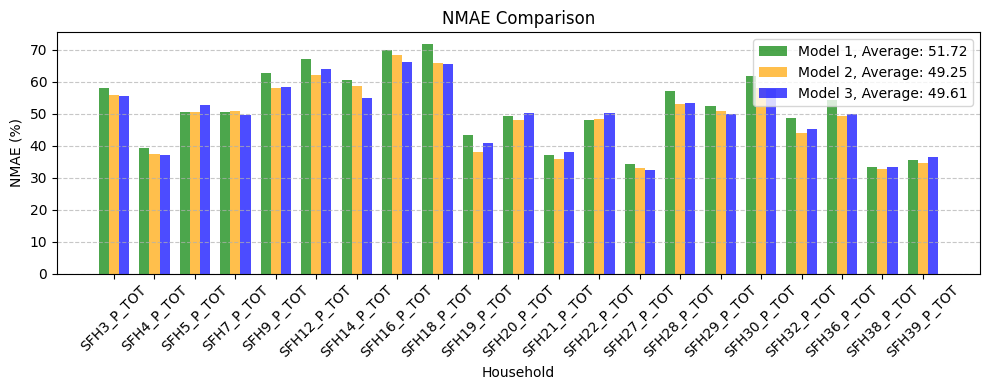

In [735]:
# Plot NMAEs
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
bar_width = 0.25
index = np.arange(len(nmae_results_m1.keys()))

plt.bar(index, nmae_results_m1.values(), bar_width, label=f'Model 1, Average: {nmae_average_m1:.2f}', color='green', alpha=0.7)
plt.bar(index + bar_width, nmae_results_m2.values(), bar_width, label=f'Model 2, Average: {nmae_average_m2:.2f}', color='orange', alpha=0.7)
plt.bar(index + 2 * bar_width, nmae_results_m3.values(), bar_width, label=f'Model 3, Average: {nmae_average_m3:.2f}', color='blue', alpha=0.7)

plt.xlabel('Household')
plt.ylabel('NMAE (%)')
plt.title('NMAE Comparison')
plt.xticks(index + bar_width, nmae_results_m1.keys(), rotation=45)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()



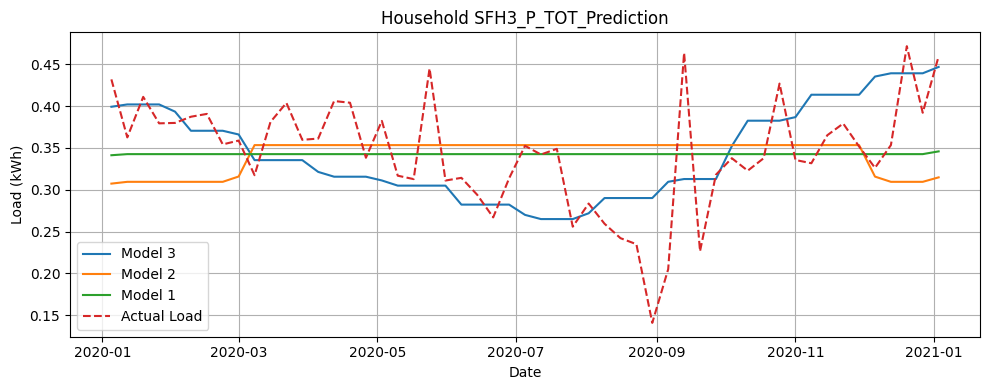

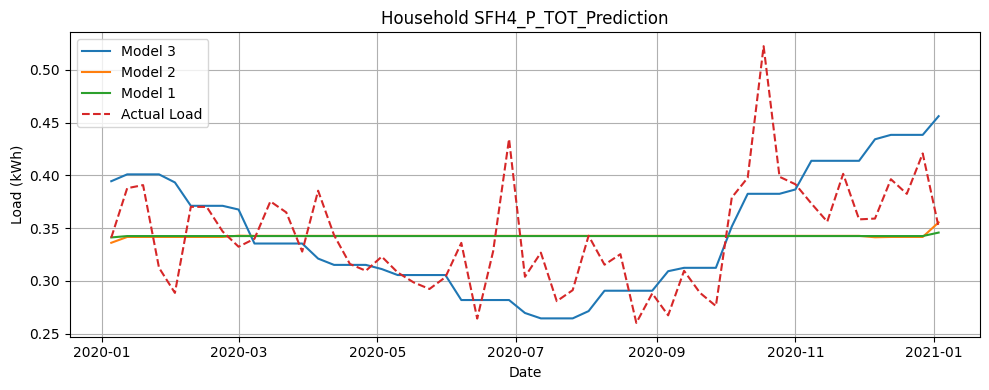

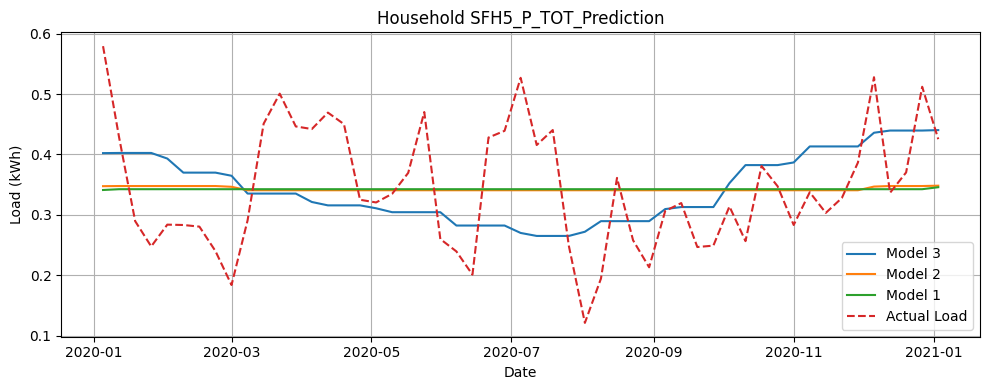

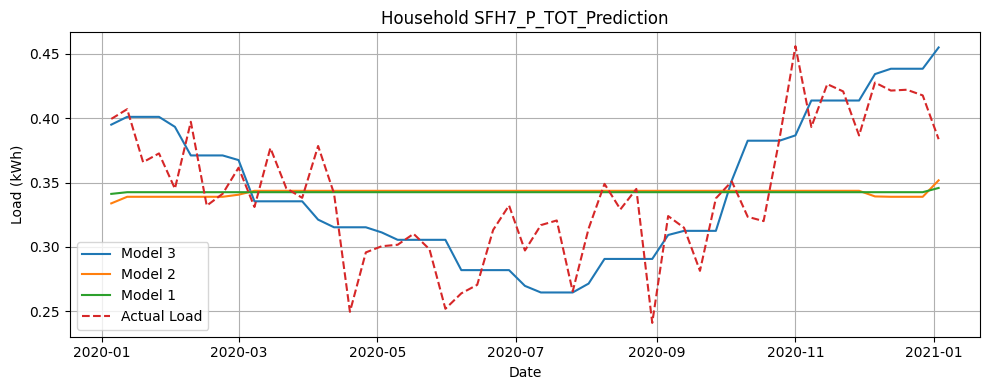

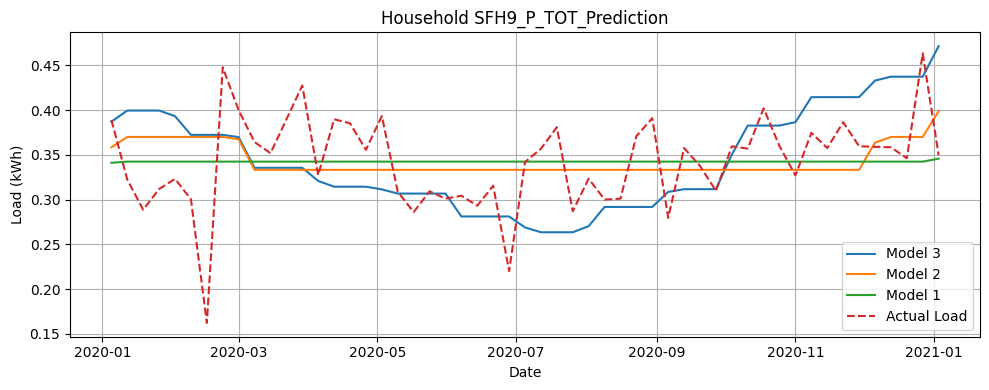

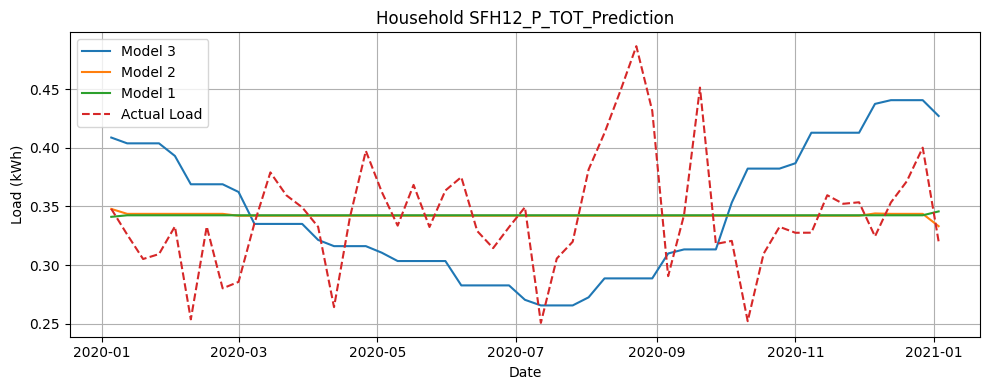

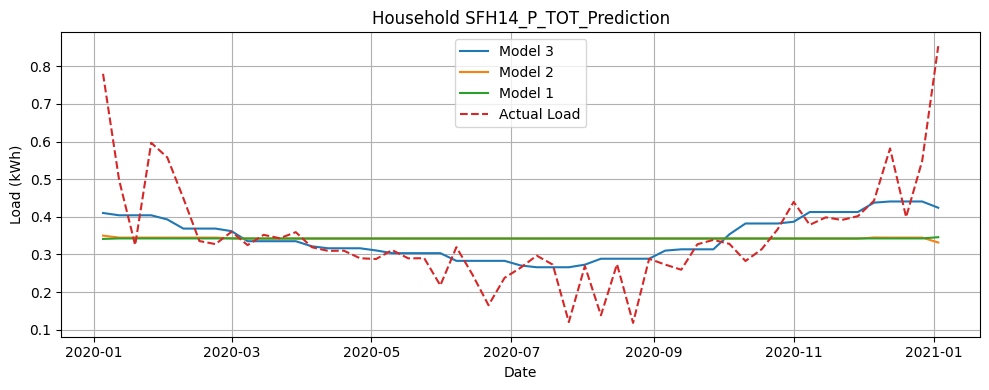

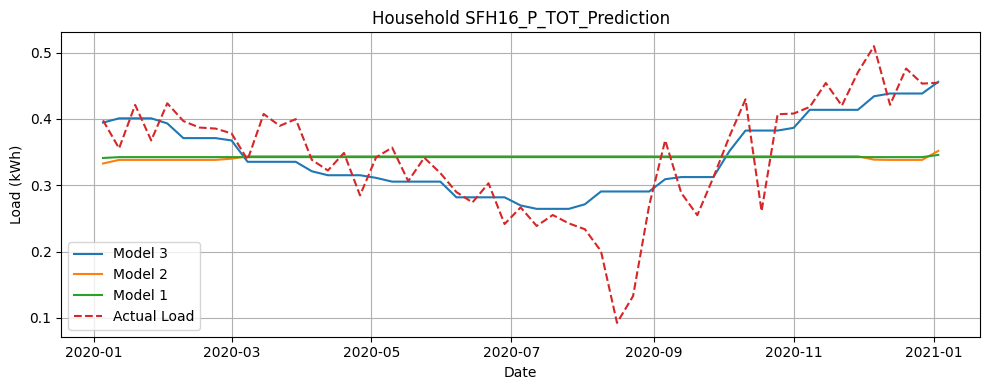

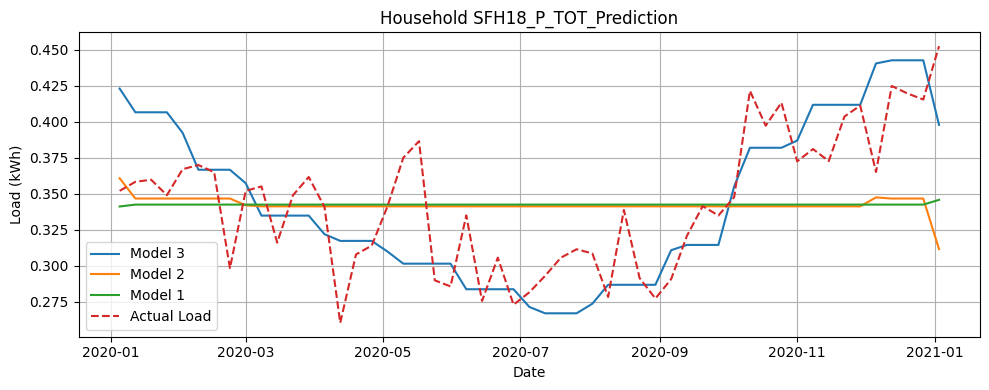

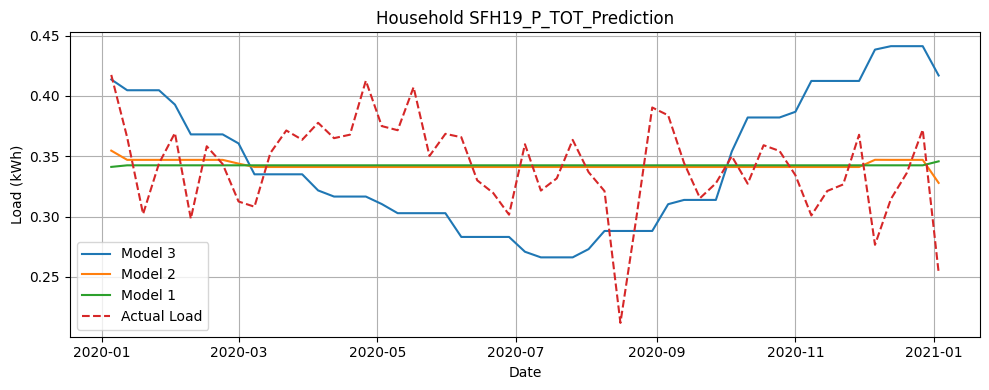

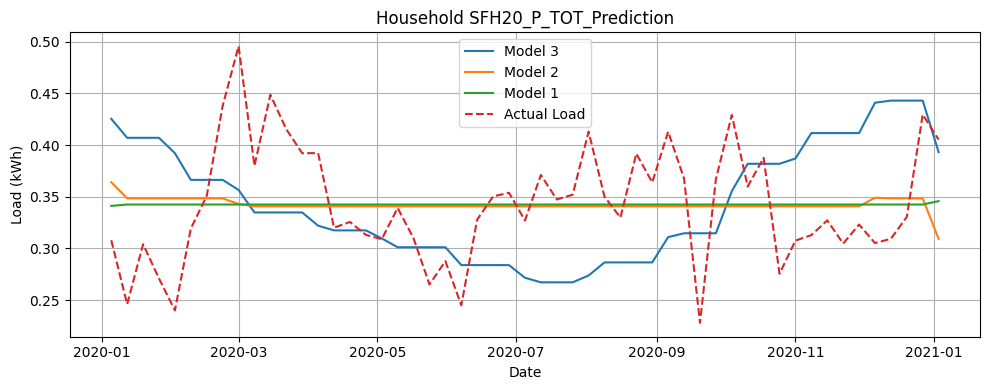

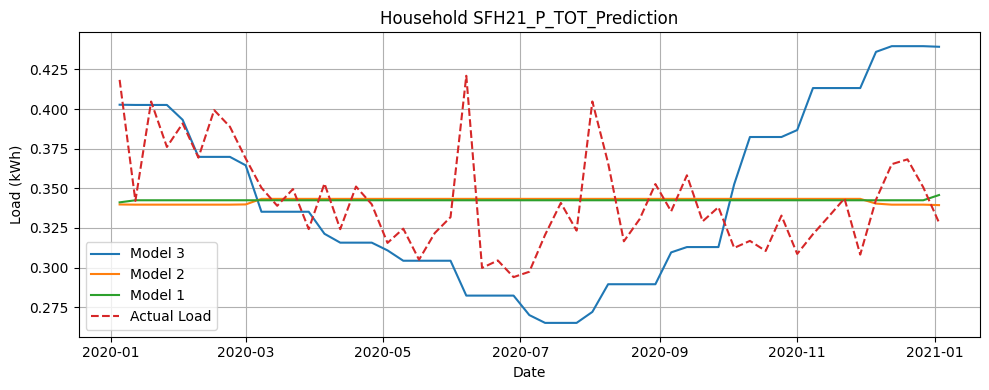

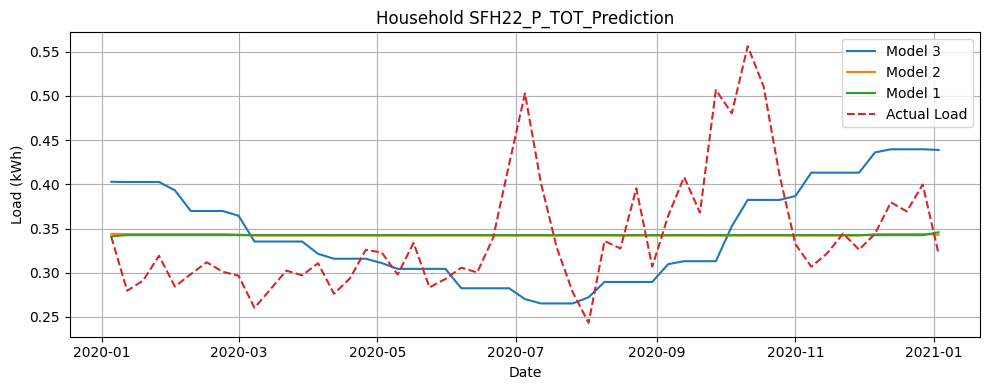

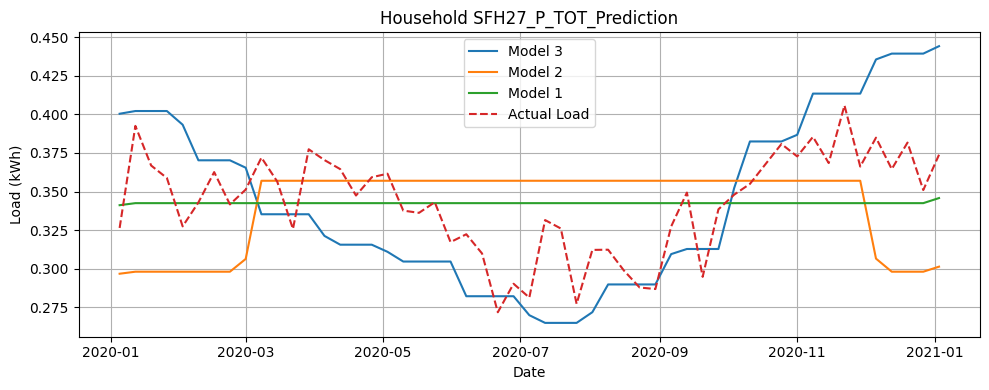

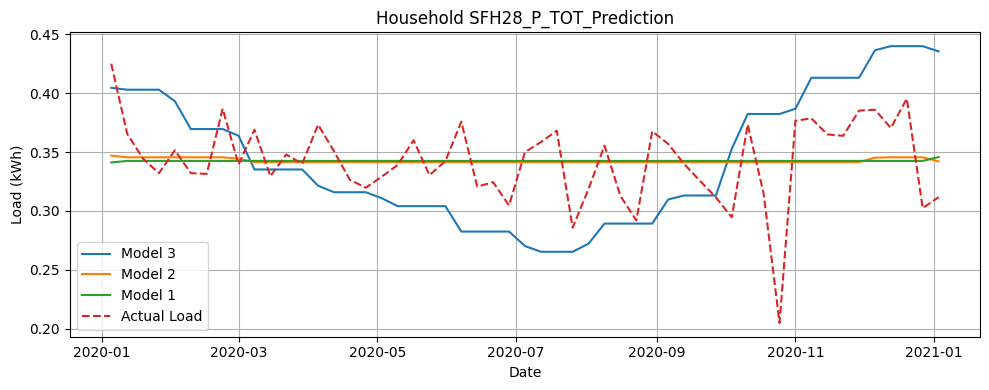

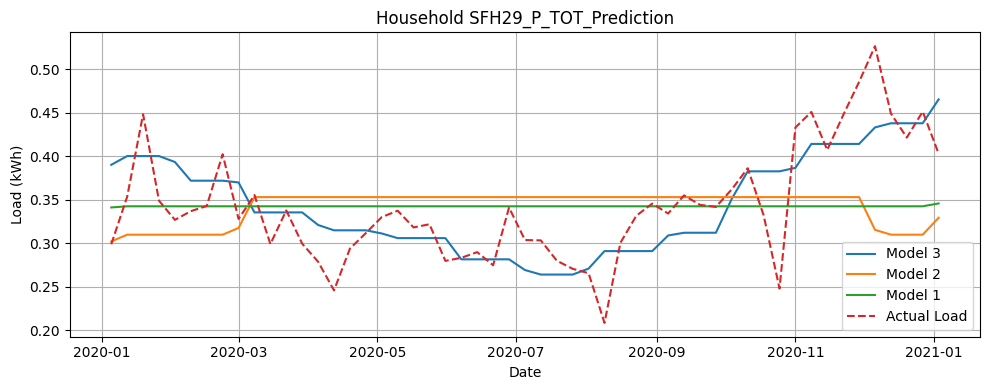

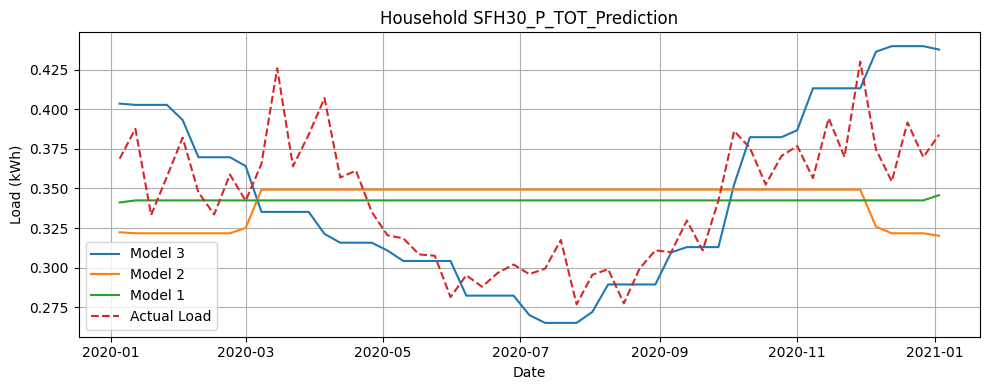

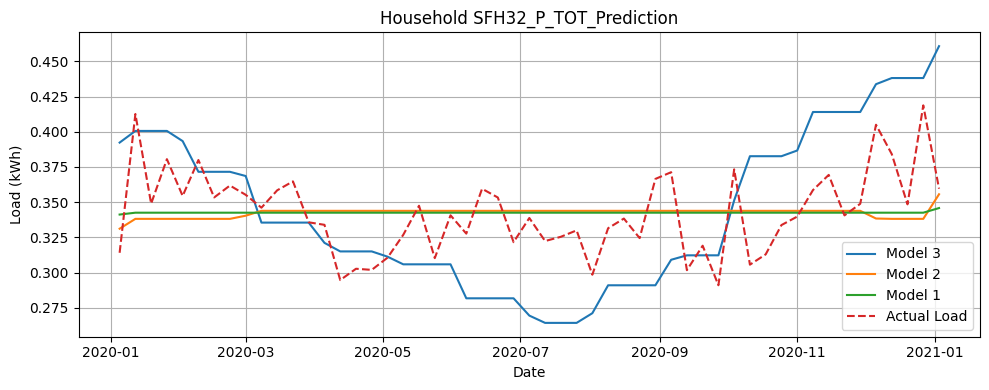

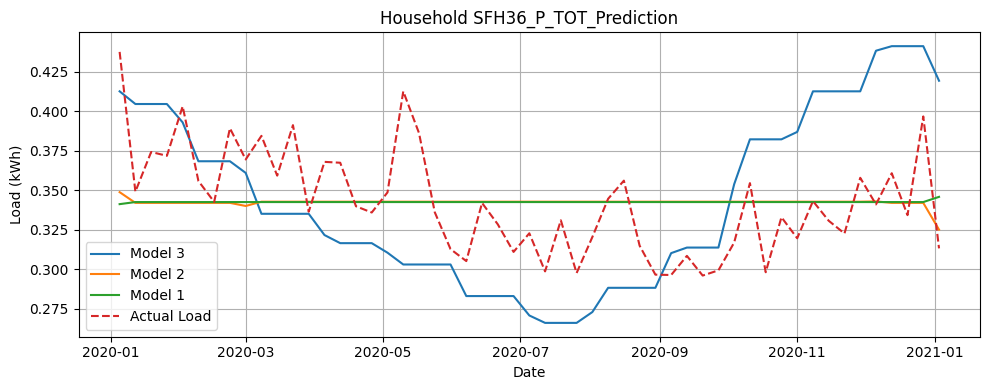

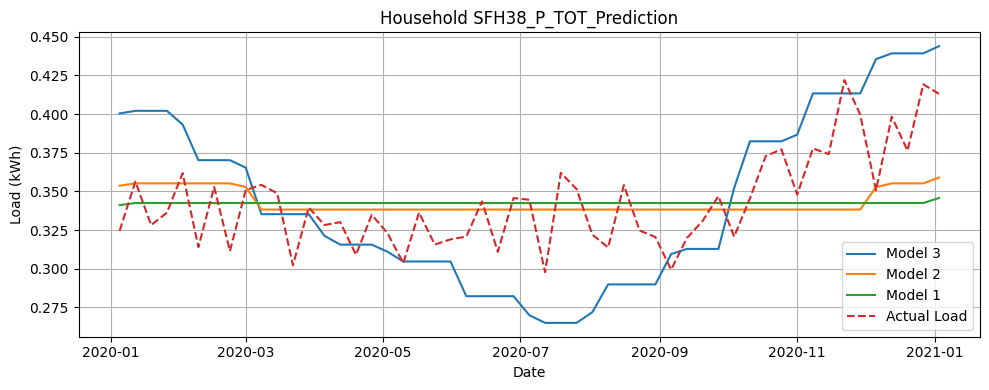

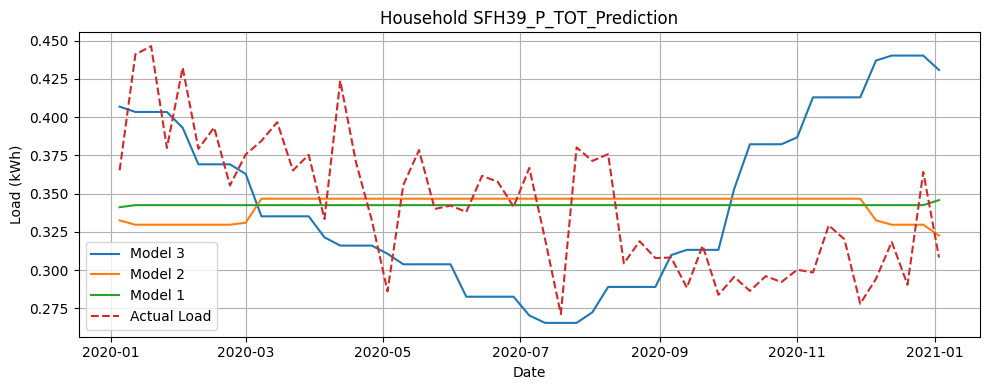

In [677]:
# smooth on weekly basis
model3_prediction_2020_weekly = model3_prediction_2020.resample('W').mean()
model2_prediction_2020_weekly = model2_prediction_2020.resample('W').mean()
model1_prediciton_2020_weekly = model1_prediciton_2020['H00_predicted [kWh]'].resample('W').mean()
actual_load_profile2020 = actual_load_profile2020.resample('W').mean()

# Plot Predicted Load Profile for 2020 for each household
for household in model3_prediction_2020_weekly.columns:
    plt.figure(figsize=(10, 4))
    plt.plot(model3_prediction_2020_weekly.index, model3_prediction_2020_weekly[household], label="Model 3")
    plt.plot(model2_prediction_2020_weekly.index, model2_prediction_2020_weekly[household], label="Model 2")
    plt.plot(model1_prediciton_2020_weekly.index, model1_prediciton_2020_weekly, label="Model 1")
    plt.plot(actual_load_profile2020.index, actual_load_profile2020[household.replace('_Prediction', '')], label="Actual Load", linestyle='--')
    plt.title(f'Household {household}')
    plt.xlabel('Date')
    plt.ylabel('Load (kWh)')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


# Dynamic Price Difference



Preise Plotten

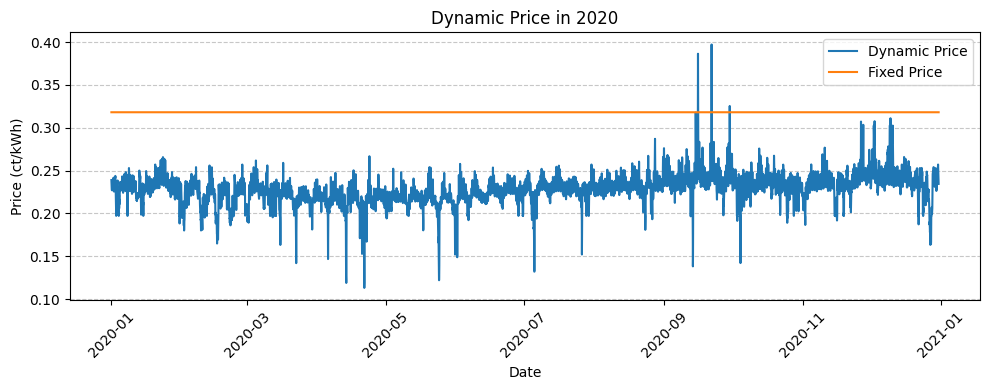

In [744]:
#plot dynamic_price_per_kwh_2020
plt.figure(figsize=(10,4))
plt.plot(dynamic_price_per_kwh_2020.index, dynamic_price_per_kwh_2020, label='Dynamic Price')
plt.plot(dynamic_price_per_kwh_2020.index, [0.3181]*len(dynamic_price_per_kwh_2020), label='Fixed Price')
plt.xlabel('Date')
plt.ylabel('Price (ct/kWh)')
plt.title('Dynamic Price in 2020')
plt.xticks(rotation=45)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

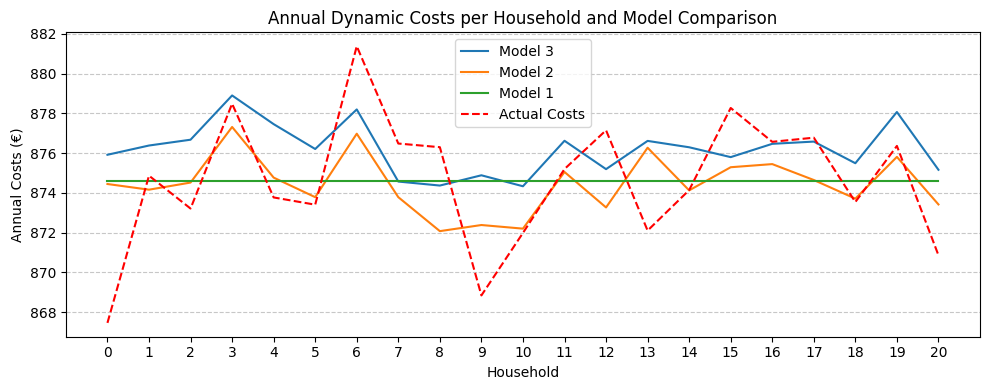

In [766]:
# Annual dynamic prices per Household and Model Comparison
dynamic_costs_allhouseholds_m3
dynamic_costs_allhouseholds_m2
dynamic_costs_allhouseholds_m1

#Plot values as table with numbers

plt.figure(figsize=(10,4))
plt.plot(dynamic_costs_allhouseholds_m3, label='Model 3')
plt.plot(dynamic_costs_allhouseholds_m2, label='Model 2')
plt.plot(dynamic_costs_allhouseholds_m1, label='Model 1')
plt.plot(dynamic_costs_allhouseholds_actual, label = 'Actual Costs', linestyle='--', color='red')
plt.xlabel('Household')
plt.xticks(np.arange(0, len(dynamic_costs_allhouseholds_actual), 1))
plt.ylabel('Annual Costs (€)')
plt.title('Annual Dynamic Costs per Household and Model Comparison')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()




# Write results in json datei

In [768]:
#Write results in json 

results = { 
     "Run Date": random_start_date.isoformat(),  # Konvertierung in einen String
    "NMAE": {
        "Model 1": nmae_results_m1,
        "Model 2": nmae_results_m2,
        "Model 3": nmae_results_m3
    },
    "Average NMAE": {
        "Model 1": nmae_average_m1,
        "Model 2": nmae_average_m2,
        "Model 3": nmae_average_m3
    },
    "Annual Predicted Costs": {
        "Model 1": dynamic_costs_allhouseholds_m1,
        "Model 2": dynamic_costs_allhouseholds_m2,
        "Model 3": dynamic_costs_allhouseholds_m3,
        "Static Prices": annual_predicted_costs_static_prices_results_m3,
        "Actual Costs": dynamic_costs_allhouseholds_actual
    }
}


# Schreibe die Daten in eine Datei namens "results.json"
with open("results.json", "w") as f:
    json.dump(results, f, indent=4)

print("Die Ergebnisse wurden in results.json gespeichert.")

Die Ergebnisse wurden in results.json gespeichert.
